# Assignment 1: Data Profiling (EDA) Report

**Industry domain:** Entertainment / Streaming Services

**Scenario:** An automated data pipeline for a movie streaming service's *Guess You Like* feature.

**Team members**

| Name | Matric number |
|---|---|
| LU JUNMING | A214112 |
| LIN MINGXU | A214110 |
| ZHAO YIHAN | A207334 |
| BAI XINRAN | A223106 |

**Dataset:** Movie Reviews Dataset — Zenodo record [14203180](https://zenodo.org/records/14203180) (DOI: `10.5281/zenodo.14203180`), file `movie_reviews.csv`, CC BY 4.0.

**Scope of this notebook:** data profiling, exploratory data analysis (EDA), and data-quality handling only. We do not build a recommender, train a pre-trained model, or evaluate recommendation quality. The model and the *Guess You Like* feature are the business context that motivates the data checks.

## 1. Title and Team Members

- **Assignment:** Assignment 1 — Data Profiling (EDA) Report
- **Group project theme:** Entertainment / Streaming Services
- **Team members:** LU JUNMING (A214112), LIN MINGXU (A214110), ZHAO YIHAN (A207334), BAI XINRAN (A223106)
- **Notebook:** `Assignment1_EDA.ipynb`
- **Repository files:** `README.md`, `requirements.txt`, `data/README.md`

This notebook is written so that it can be executed from top to bottom in a fresh clone. If `data/movie_reviews.csv` is absent, Section 5 downloads it automatically from the public Zenodo URL. No API key, account, or secret is required.

## 2. Business Scenario

A movie streaming service wants to improve user retention and reduce *choice paralysis* with a **"Guess You Like"** feature that recommends movies similar to what a viewer has already enjoyed. In the proposed architecture, an automated batch pipeline ingests movie metadata and critic reviews, enriches the batch data with a pre-trained review-analysis model (for example, sentiment or review-embedding extraction), and uses the resulting representations to retrieve similar movies.

The quality of that pipeline depends on the quality of its inputs. Missing metadata, duplicated reviews, inconsistent titles, impossible years, and text that is only boilerplate can all distort similarity: a film can be linked to the wrong neighbours, popular films can dominate, and a review can be counted twice. For that reason the data must be profiled and cleaned **before** it is handed to an automated batch job and a pre-trained model, where errors would be repeated silently on every run.

This notebook therefore asks what is wrong with the review and metadata tables, how each problem should be treated, and which risks remain. It does not evaluate whether the recommender improves retention; that would require user-behaviour data and an implemented recommendation model, neither of which is in scope for Assignment 1.

## 3. Data Source

| Item | Value |
|---|---|
| Dataset | Movie Reviews Dataset |
| Source page | https://zenodo.org/records/14203180 |
| Direct file URL | https://zenodo.org/records/14203180/files/movie_reviews.csv?download=1 |
| DOI | 10.5281/zenodo.14203180 |
| Licence | CC BY 4.0 |
| Creators (as listed on Zenodo) | Jad Doghman; Wael Khreich |
| Publication date (Zenodo) | 2024-11-22 |
| File | `movie_reviews.csv` (93,715,558 bytes) |
| SHA-256 of the file used here | `ff337b14fbd7b6d25278e81d62de71c6d6d346bf61548d918455c666eb7f6559` |

**How the data was obtained.** The CSV is downloaded programmatically from the Zenodo URL above by the next code cell and stored at the relative path `data/movie_reviews.csv`. The download is checked against the expected byte size, and the SHA-256 digest is printed so that another team can verify that they are profiling the same file. If the download fails, the notebook stops with an explicit error; it does not substitute synthetic data.

**What the dataset contains.** The Zenodo record describes the data as professional movie-critic reviews derived from the Cornell movie-review collection, enriched with metadata from the OMDb API: movie title, release year, MPAA-style rating, genre, director(s), writer(s), cast, plot, plus the gender of the first-listed actor, director, and writer.

**A documentation discrepancy to keep in mind.** The Zenodo description says the dataset contains **17,165 reviews across 2,544 unique movies**. The distributed `movie_reviews.csv` actually contains **18,862 rows across 2,962 distinct `movie_name` values**. We analyse the file we can verify, and we report the mismatch in Section 11 rather than treating the record description as ground truth.

**Important limitation of the source.** These are *professional critic reviews*, not reviews written by subscribers of a streaming platform. The data is used here as a realistic stand-in to practise data-quality diagnosis in a streaming-recommendation scenario; it is not a sample of platform-user behaviour.

## 4. Research Questions

The profiling and EDA are organised around these questions:

1. **RQ1 — Missing values:** Which review fields and movie-metadata fields are missing, how much is missing, and are there empty or whitespace-only values that `isna()` does not catch?
2. **RQ2 — Duplicates:** Are there exact duplicate rows, duplicate review texts, duplicate `review_id` values, or duplicate movie records? Which repeated observations are legitimate (several critics reviewing the same film) and which are genuine duplication?
3. **RQ3 — Outliers:** Are review lengths, reviews-per-movie counts, reviewer activity, or year values extreme? Which extremes are real and which are errors?
4. **RQ4 — Consistency and formats:** Are titles, genres, ratings, years, and text encodings consistent? Do the two year fields agree? Can movie entities be matched reliably?
5. **RQ5 — Imbalance:** Are movies, years, genres, ratings, critics, and gender groups represented evenly enough for a similarity model?
6. **RQ6 — Impact on *Guess You Like*:** Which of these problems would damage a review-analysis and similar-movie pipeline, and what must be fixed or flagged before modelling?
7. **RQ7 — Privacy and bias:** Does the data contain personally identifiable information, and which sampling biases would be inherited by a recommender trained on it?

## 5. Loading the Dataset

The cell below:

1. creates `data/` if necessary;
2. reuses `data/movie_reviews.csv` when it already has the expected size;
3. otherwise downloads the file from Zenodo using HTTP range requests (falling back to a single stream if the server does not support ranges), verifying the size and SHA-256;
4. stops with a clear `RuntimeError` if the download fails — no fake data is generated;
5. validates the **actual** schema before any analysis.

All paths are relative to the notebook directory. The download is roughly 94 MB and can take a few minutes on a slow connection.

In [1]:
%matplotlib inline

import hashlib
import html
import math
import re
import shutil
import time
import urllib.error
import urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 110)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---------------------------------------------------------------------------
# Relative paths and public source metadata
# ---------------------------------------------------------------------------
DATA_DIR = Path("data")
DATA_PATH = DATA_DIR / "movie_reviews.csv"
DATASET_URL = "https://zenodo.org/records/14203180/files/movie_reviews.csv?download=1"
RECORD_URL = "https://zenodo.org/records/14203180"
DOI = "10.5281/zenodo.14203180"
EXPECTED_BYTES = 93_715_558
MIN_BYTES = 90_000_000
EXPECTED_SHA256 = "ff337b14fbd7b6d25278e81d62de71c6d6d346bf61548d918455c666eb7f6559"

# ---------------------------------------------------------------------------
# Chart palette: fixed-order, colour-blind-safe categorical slots
# (validated with the dataviz palette validator; see README)
# ---------------------------------------------------------------------------
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE, BASELINE = "#e1e0d9", "#fcfcfb", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial"],
    "font.size": 9.5,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.labelsize": 9.5,
    "axes.labelcolor": INK_2,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.edgecolor": BASELINE,
    "axes.linewidth": 0.8,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "figure.dpi": 110,
})

# ---------------------------------------------------------------------------
# Text and privacy helpers
# ---------------------------------------------------------------------------
EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+")
URL_RE = re.compile(r"(?i)https?://\S+|www\.\S+")
PHONE_RE = re.compile(r"(?<![\d.])(?:\+\d{1,3}[ .-]?)?(?:\(?\d{3}\)?[ .-]?)\d{3}[ .-]\d{4}(?![\d.])")
IP_RE = re.compile(r"\b\d{1,3}(?:\.\d{1,3}){3}\b")
FOOTER_MARKER = "The review above was posted to the"


def strip_footer(text):
    """Remove the legal/Usenet footer that is appended to every source review."""
    idx = text.find(FOOTER_MARKER)
    return text[:idx] if idx != -1 else text


def repair_mojibake(text):
    """Repair the few double-encoded UTF-8 fragments (for example 'cliché')."""
    if ("Ã" in text) or ("â€" in text):
        try:
            return text.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return text
    return text


def standardize_text(value):
    """Clean review text and redact direct contact identifiers."""
    s = "" if pd.isna(value) else str(value)
    s = html.unescape(s)
    s = re.sub(r"<[^>]+>", " ", s)          # HTML tags
    s = strip_footer(s)                      # boilerplate appended to every review
    s = repair_mojibake(s)                   # encoding artefacts
    s = EMAIL_RE.sub(" [EMAIL_REDACTED] ", s)
    s = URL_RE.sub(" [URL_REDACTED] ", s)
    s = PHONE_RE.sub(" [PHONE_REDACTED] ", s)
    s = IP_RE.sub(" [IP_REDACTED] ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s


def hash_reviewer(name):
    """Pseudonymise a reviewer byline; the raw name is never needed downstream."""
    key = str(name).strip().lower()
    return "critic_" + hashlib.sha256(key.encode("utf-8")).hexdigest()[:10]


def normalize_title(title):
    """Move a trailing English article to the front: 'Matrix, The' -> 'The Matrix'."""
    t = re.sub(r"\s+", " ", str(title).strip())
    m = re.match(r"^(.*),\s*(The|A|An)$", t)
    if m:
        t = f"{m.group(2)} {m.group(1)}"
    return t


def normalize_genre(value):
    """Represent a genre list as a sorted set so ordering does not create new categories."""
    if pd.isna(value):
        return "Unknown"
    parts = sorted({g.strip() for g in str(value).split(",") if g.strip()})
    return ", ".join(parts) if parts else "Unknown"


def decorate(ax, grid_axis="y"):
    """Recessive hairline grid and axes for every chart."""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(BASELINE)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9)


# ---------------------------------------------------------------------------
# Download helpers (only used when data/movie_reviews.csv is missing)
# ---------------------------------------------------------------------------
_UA = "Mozilla/5.0 (compatible; Assignment1-EDA/1.0)"


def _probe_remote(url, timeout=60):
    req = urllib.request.Request(url, headers={"Range": "bytes=0-0", "User-Agent": _UA})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        content_range = resp.headers.get("Content-Range", "")
        if resp.status == 206 and "/" in content_range:
            return int(content_range.rsplit("/", 1)[1]), True
        length = resp.headers.get("Content-Length")
        return (int(length) if length else None), False


def _download_range(url, start, end, dest, attempts=6):
    want = end - start + 1
    if dest.exists() and dest.stat().st_size == want:
        return
    headers = {"Range": f"bytes={start}-{end}", "User-Agent": _UA}
    last_error = None
    for attempt in range(attempts):
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=headers), timeout=180) as resp:
                data = resp.read()
            if len(data) != want:
                raise IOError(f"received {len(data):,} bytes, expected {want:,}")
            dest.write_bytes(data)
            return
        except Exception as exc:  # retry transient network failures per chunk
            last_error = exc
            time.sleep(2 + 2 * attempt)
    raise IOError(f"chunk {start}-{end} failed after {attempts} attempts: {last_error}")


def _download_parallel(url, dest, total, chunk=1_000_000, workers=8):
    part_dir = dest.parent / ".download_parts"
    shutil.rmtree(part_dir, ignore_errors=True)
    part_dir.mkdir(parents=True, exist_ok=True)
    n_chunks = math.ceil(total / chunk)
    print(f"Downloading {total / 1e6:.1f} MB in {n_chunks} chunks with {workers} workers ...")
    try:
        with ThreadPoolExecutor(max_workers=workers) as pool:
            futures = []
            for i in range(n_chunks):
                start = i * chunk
                end = min(start + chunk, total) - 1
                futures.append(pool.submit(_download_range, url, start, end, part_dir / f"{i:05d}.part"))
            done = 0
            for future in as_completed(futures):
                future.result()
                done += 1
                if done % 20 == 0 or done == n_chunks:
                    print(f"  {done}/{n_chunks} chunks complete")
        tmp = dest.with_suffix(".download")
        with open(tmp, "wb") as out:
            for i in range(n_chunks):
                out.write((part_dir / f"{i:05d}.part").read_bytes())
        tmp.replace(dest)
    finally:
        shutil.rmtree(part_dir, ignore_errors=True)


def _download_stream(url, dest):
    tmp = dest.with_suffix(".download")
    req = urllib.request.Request(url, headers={"User-Agent": _UA})
    with urllib.request.urlopen(req, timeout=180) as resp, open(tmp, "wb") as out:
        total = int(resp.headers.get("Content-Length") or 0)
        received = 0
        last_report = time.time()
        while True:
            block = resp.read(512 * 1024)
            if not block:
                break
            out.write(block)
            received += len(block)
            if time.time() - last_report > 15:
                share = f"{received / total * 100:5.1f}%" if total else f"{received / 1e6:.1f} MB"
                print(f"  downloaded {share}")
                last_report = time.time()
    tmp.replace(dest)


def sha256_file(path, block_size=1 << 20):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()


def ensure_dataset():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    if DATA_PATH.exists() and DATA_PATH.stat().st_size == EXPECTED_BYTES:
        print(f"Using existing file: {DATA_PATH} ({DATA_PATH.stat().st_size:,} bytes)")
        return
    if DATA_PATH.exists():
        print(f"Existing file has unexpected size ({DATA_PATH.stat().st_size:,} bytes); re-downloading.")
    try:
        total, supports_ranges = _probe_remote(DATASET_URL)
        if total is None:
            raise IOError("the server did not report the file size")
        print(f"Remote file size: {total:,} bytes (range requests: {supports_ranges})")
        if supports_ranges:
            _download_parallel(DATASET_URL, DATA_PATH, total)
        else:
            _download_stream(DATASET_URL, DATA_PATH)
    except Exception as exc:
        DATA_PATH.unlink(missing_ok=True)
        (DATA_DIR / "movie_reviews.download").unlink(missing_ok=True)
        shutil.rmtree(DATA_DIR / ".download_parts", ignore_errors=True)
        raise RuntimeError(
            "Dataset download failed. "
            f"URL: {DATASET_URL}. Error: {exc}. "
            f"Please download the file manually and save it as '{DATA_PATH}', then re-run this cell."
        ) from exc

    size = DATA_PATH.stat().st_size
    if size < MIN_BYTES:
        DATA_PATH.unlink(missing_ok=True)
        raise RuntimeError(
            f"Downloaded file is too small ({size:,} bytes; expected about {EXPECTED_BYTES:,}). "
            f"Delete '{DATA_PATH}' and try again, or download it manually from {RECORD_URL}."
        )
    digest = sha256_file(DATA_PATH)
    if digest != EXPECTED_SHA256:
        print("WARNING: SHA-256 differs from the reference copy used in this report.")
        print(f"  expected: {EXPECTED_SHA256}")
        print(f"  actual  : {digest}")
    else:
        print("SHA-256 verified.")


ensure_dataset()

df = pd.read_csv(DATA_PATH, encoding="utf-8")
required_columns = {
    "review_id", "movie_name", "year", "reviewer_name", "review_text", "rated",
    "year_api", "genre", "directors", "writers", "actors", "plot", "first_genre",
    "first_actor", "first_director", "first_writer",
    "first_actor_gender", "first_director_gender", "first_writer_gender",
}
missing_required = sorted(required_columns - set(df.columns))
if missing_required:
    raise ValueError(
        f"Unexpected schema. Missing required columns: {missing_required}. "
        f"Actual columns: {list(df.columns)}"
    )

df_raw = df.copy()  # preserved untouched for before/after comparisons

print(f"\nLoaded: {DATA_PATH}")
print(f"Rows x columns: {df.shape[0]:,} x {df.shape[1]}")
print(f"File size: {DATA_PATH.stat().st_size:,} bytes")
print(f"Columns: {list(df.columns)}")
print(f"In-memory size: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

Using existing file: data\movie_reviews.csv (93,715,558 bytes)

Loaded: data\movie_reviews.csv
Rows x columns: 18,862 x 20
File size: 93,715,558 bytes
Columns: ['Unnamed: 0', 'review_id', 'movie_name', 'year', 'reviewer_name', 'review_text', 'rated', 'year_api', 'genre', 'directors', 'writers', 'actors', 'plot', 'first_genre', 'first_actor', 'first_director', 'first_writer', 'first_actor_gender', 'first_director_gender', 'first_writer_gender']
In-memory size: 108.2 MB


**Output explained.** The file loads as **18,862 rows × 20 columns**. The first column, `Unnamed: 0`, is an exported pandas index and duplicates `review_id`; it is not a real variable. `review_id` is unique, `movie_name` identifies 2,962 distinct films, and `reviewer_name` identifies 1,218 bylines. The table is one row per review, with movie metadata repeated on every row for that film. The in-memory footprint is about 108 MB because `review_text` is long.

The schema matches the expected 20 fields. `year` is floating point because it has missing values; `year_api` is an integer movie-release year supplied by the OMDb enrichment. There is **no numeric review score, no duration, and no language column**, so we will not invent analyses for them.

## 6. Initial Data Inspection

We inspect the size, a few raw rows, a random sample (reviewer bylines are masked and review text is truncated), data types, unique-value counts, numeric summaries, and basic text statistics. Every number below is produced by the code, not assumed.

In [2]:
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print(f"Distinct movie_name: {df.movie_name.nunique():,} | Distinct reviewer_name: {df.reviewer_name.nunique():,}")
print(f"Distinct review_id: {df.review_id.nunique():,} | review_id min/max: {df.review_id.min():,}/{df.review_id.max():,}")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

print("\nFirst three rows (reviewer name masked, review text truncated):")
first = df.head(3).copy()
first["review_text"] = first.review_text.str[:110] + "..."
display(first.drop(columns=["reviewer_name", "review_text"]).assign(review_snippet=first.review_text))

print("Random sample of five rows:")
sample = df.sample(5, random_state=RANDOM_STATE).copy()
sample["reviewer_name"] = "[masked]"
sample["review_text"] = sample.review_text.str[:90] + "..."
display(sample[["review_id", "movie_name", "year", "year_api", "rated", "first_genre", "reviewer_name", "review_text"]])

print("\nDataFrame info:")
df.info()

Rows: 18,862 | Columns: 20
Distinct movie_name: 2,962 | Distinct reviewer_name: 1,218
Distinct review_id: 18,862 | review_id min/max: 1/18,862
Exact duplicate rows: 0

First three rows (reviewer name masked, review text truncated):


,Unnamed: 0,review_id,movie_name,year,rated,year_api,genre,directors,writers,actors,plot,first_genre,first_actor,first_director,first_writer,first_actor_gender,first_director_gender,first_writer_gender,review_snippet
0,0,1,Lethal Weapon 3,1992.0,R,1992,"Action, Crime, Thriller",Richard Donner,"Jeffrey Boam, Robert Mark Kamen, Shane Black","Mel Gibson, Danny Glover, Joe Pesci",Martin Riggs and Roger Murtaugh pursue a former LAPD officer who uses his knowledge of police procedure an...,Action,Mel Gibson,Richard Donner,Jeffrey Boam,female,male,male,"About 20 minutes into LETHAL WEAPON 3, my nephew turned to me and\nasked, ""Does this movie have a plot?"" ..."
1,1,2,Lethal Weapon 3,1999.0,R,1992,"Action, Crime, Thriller",Richard Donner,"Jeffrey Boam, Robert Mark Kamen, Shane Black","Mel Gibson, Danny Glover, Joe Pesci",Martin Riggs and Roger Murtaugh pursue a former LAPD officer who uses his knowledge of police procedure an...,Action,Mel Gibson,Richard Donner,Jeffrey Boam,female,male,male,"LETHAL WEAPON 3 is a film directed by Richard Donner, written by\nJeffrey Boam. It stars Mel Gibson, Dann..."
2,2,3,Lethal Weapon 3,1995.0,R,1992,"Action, Crime, Thriller",Richard Donner,"Jeffrey Boam, Robert Mark Kamen, Shane Black","Mel Gibson, Danny Glover, Joe Pesci",Martin Riggs and Roger Murtaugh pursue a former LAPD officer who uses his knowledge of police procedure an...,Action,Mel Gibson,Richard Donner,Jeffrey Boam,female,male,male,"120 min., R, Comedy/Action, 1992\nDirector: Richard Donner\nCast: Danny Glover, Mel Gibson, Joe Pesci, Ren..."


Random sample of five rows:


,review_id,movie_name,year,year_api,rated,first_genre,reviewer_name,review_text
10322,10323,Frequency,1987.0,2000,PG-13,Crime,[masked],Logical time travel movies are a near-impossibility. Considering that\nthe skeptic's best a...
2480,2481,Near Dark,1999.0,1987,R,Horror,[masked],"On the face of it, there seems little that is exceptional,\nstorywise,with this reworking o..."
6462,6463,Spawn,1997.0,1997,PG-13,Action,[masked],"Once upon a time, many years ago when the earth was still young, I\nread comic books. In f..."
4128,4129,Lost in Yonkers,1998.0,1993,PG,Comedy,[masked],"Neil Simon built his reputation on warm, whimsical comedies with\noccasional pieces of real..."
6829,6830,"World Is Not Enough, The",1999.0,2006,NaN,Documentary,[masked],I'll admit up front that I've only become a big fan of the James Bond films \nafter I saw G...



DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18862 entries, 0 to 18861
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             18862 non-null  int64  
 1   review_id              18862 non-null  int64  
 2   movie_name             18862 non-null  object 
 3   year                   18491 non-null  float64
 4   reviewer_name          18862 non-null  object 
 5   review_text            18862 non-null  object 
 6   rated                  17201 non-null  object 
 7   year_api               18862 non-null  int64  
 8   genre                  18855 non-null  object 
 9   directors              18532 non-null  object 
 10  writers                17909 non-null  object 
 11  actors                 18647 non-null  object 
 12  plot                   18214 non-null  object 
 13  first_genre            18855 non-null  object 
 14  first_actor            18647 non-null

In [3]:
column_profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(column_profile)

print("Numeric summary (year fields):")
display(df[["year", "year_api"]].describe().T.round(2))

raw_chars = df.review_text.str.len()
raw_words = df.review_text.str.split().str.len()
text_summary = pd.DataFrame({
    "characters": raw_chars.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]),
    "words": raw_words.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]),
}).T
display(text_summary.round(1))

print("Categorical level counts:")
display(pd.DataFrame({
    "rated": df.rated.value_counts(dropna=False).head(10),
    "first_genre": df.first_genre.value_counts(dropna=False).head(10),
    "first_actor_gender": df.first_actor_gender.value_counts(dropna=False),
}))

,dtype,non_null,missing,missing_pct,unique
Unnamed: 0,int64,18862,0,0.00,18862
review_id,int64,18862,0,0.00,18862
movie_name,object,18862,0,0.00,2962
year,float64,18491,371,1.97,86
reviewer_name,object,18862,0,0.00,1218
review_text,object,18862,0,0.00,18746
rated,object,17201,1661,8.81,19
year_api,int64,18862,0,0.00,107
genre,object,18855,7,0.04,405
directors,object,18532,330,1.75,1885


Numeric summary (year fields):


,count,mean,std,min,25%,50%,75%,max
year,18491.0,1993.9,11.03,1913.0,1994.0,1997.0,1999.0,2001.0
year_api,18862.0,1996.5,11.02,1907.0,1996.0,1998.0,2000.0,2023.0


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
characters,18862.0,4580.6,1923.8,585.0,1731.0,2262.0,3315.0,4315.0,5420.0,7896.0,11046.9,32895.0
words,18862.0,757.9,327.9,84.0,276.0,361.0,545.0,713.0,898.0,1322.0,1843.8,5792.0


Categorical level counts:


,rated,first_genre,first_actor_gender
Action,NaN,3944.0,NaN
Adventure,NaN,771.0,NaN
Animation,NaN,531.0,NaN
Approved,192.0,NaN,NaN
Biography,NaN,911.0,NaN
Comedy,NaN,5263.0,NaN
Crime,NaN,1492.0,NaN
Documentary,NaN,1021.0,NaN
Drama,NaN,3507.0,NaN
G,327.0,NaN,NaN


**What the inspection shows.**

- The dataset is a **flat review table**: one row per critic review, with title-level metadata repeated. `review_id` runs uniquely from 1 to 18,862 and `Unnamed: 0` is identical to the row index, so one of them is redundant.
- `review_text` is never null at this stage, but its length varies from **585 to 32,895 characters**, and the minimum is suspicious: later we show that the shortest "reviews" are legal footers rather than review content.
- `year` takes only 86 distinct values (1913–2001) and is missing in 371 rows; `year_api` takes 107 values (1907–2023) and is never missing. Because reviews in this corpus cannot have been written after 2001, release years after 2001 are already a warning sign.
- `rated` has 19 distinct labels, including legacy and non-MPAA codes (`GP`, `M`, `M/PG`, `Approved`, `Passed`, `13+`, `18+`). It is a *category*, not a numeric score, so "rating out of range" cannot be assessed as a number.
- `first_genre` has 23 levels, while the full `genre` string has 405 distinct combinations — several strings describe the same genre set in a different order.
- The three gender fields contain the literal string `unknown` rather than a missing value, which would silently count as a real category if not handled.

## 7. Data Profiling

This section profiles column roles, cardinality, missingness, numeric distributions, and text length. The aim is to describe the table's structure precisely enough to decide what is usable for a review-analysis pipeline.

In [4]:
role_map = {
    "Unnamed: 0": "redundant row index",
    "review_id": "primary key",
    "movie_name": "movie identifier (title only)",
    "year": "row-level year (review record)",
    "reviewer_name": "critic byline (PII)",
    "review_text": "review body (free text)",
    "rated": "MPAA-style category",
    "year_api": "movie release year (OMDb)",
    "genre": "movie genre list",
    "directors": "movie metadata (list)",
    "writers": "movie metadata (list)",
    "actors": "movie metadata (list)",
    "plot": "movie plot summary",
    "first_genre": "derived first genre",
    "first_actor": "derived first actor",
    "first_director": "derived first director",
    "first_writer": "derived first writer",
    "first_actor_gender": "derived gender category",
    "first_director_gender": "derived gender category",
    "first_writer_gender": "derived gender category",
}

profiling = pd.DataFrame({
    "role": pd.Series(role_map),
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
    "example": [
        "0" if c == "Unnamed: 0" else
        "1" if c == "review_id" else
        "Lethal Weapon 3" if c == "movie_name" else
        "1992.0" if c == "year" else
        "[masked byline]" if c == "reviewer_name" else
        "[text, first 80 chars]" if c == "review_text" else
        "R" if c == "rated" else
        "1992" if c == "year_api" else
        "Action, Crime, Thriller" if c == "genre" else
        "[name list]" if c in {"directors", "writers", "actors"} else
        "[plot text]" if c == "plot" else
        "Action" if c == "first_genre" else
        "[name]" if c in {"first_actor", "first_director", "first_writer"} else
        "male" if c.endswith("_gender") else ""
        for c in df.columns
    ],
})
display(profiling)

print("Column groups:")
print(f"  Identifier/diagnostic columns : 2 (review_id, Unnamed: 0)")
print(f"  Review text                   : 1")
print(f"  Movie metadata (title-level)  : 7 (movie_name, year_api, rated, genre, directors, writers, actors, plot)")
print(f"  Derived helper columns        : 7 (first_* fields)")
print(f"  Row-level year field          : 1 (year)")
print(f"  PII byline                    : 1 (reviewer_name)")

,role,dtype,non_null,missing,missing_pct,unique,example
Unnamed: 0,redundant row index,int64,18862,0,0.00,18862,0
review_id,primary key,int64,18862,0,0.00,18862,1
movie_name,movie identifier (title only),object,18862,0,0.00,2962,Lethal Weapon 3
year,row-level year (review record),float64,18491,371,1.97,86,1992.0
reviewer_name,critic byline (PII),object,18862,0,0.00,1218,[masked byline]
review_text,review body (free text),object,18862,0,0.00,18746,"[text, first 80 chars]"
rated,MPAA-style category,object,17201,1661,8.81,19,R
year_api,movie release year (OMDb),int64,18862,0,0.00,107,1992
genre,movie genre list,object,18855,7,0.04,405,"Action, Crime, Thriller"
directors,movie metadata (list),object,18532,330,1.75,1885,[name list]


Column groups:
  Identifier/diagnostic columns : 2 (review_id, Unnamed: 0)
  Review text                   : 1
  Movie metadata (title-level)  : 7 (movie_name, year_api, rated, genre, directors, writers, actors, plot)
  Derived helper columns        : 7 (first_* fields)
  Row-level year field          : 1 (year)
  PII byline                    : 1 (reviewer_name)


In [5]:
print("Cardinality and balance in categorical fields:")
for col in ["rated", "first_genre", "first_actor_gender", "first_director_gender", "first_writer_gender"]:
    vc = df[col].value_counts(dropna=False)
    top_share = vc.iloc[0] / len(df) * 100
    n_levels = df[col].nunique(dropna=True)
    print(f"  {col:24s} {n_levels:>3} non-missing levels | most common: {vc.index[0]!r} ({top_share:.1f}% of rows)")

print("\nText length distribution (raw text):")
display(raw_chars.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1).to_frame("characters"))

print("\nNumeric fields: quantiles")
display(df[["year", "year_api"]].quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]).round(1))

print("\nMissing values by column (raw):")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))

Cardinality and balance in categorical fields:
  rated                     19 non-missing levels | most common: 'R' (47.5% of rows)
  first_genre               23 non-missing levels | most common: 'Comedy' (27.9% of rows)
  first_actor_gender         3 non-missing levels | most common: 'male' (70.4% of rows)
  first_director_gender      3 non-missing levels | most common: 'male' (85.0% of rows)
  first_writer_gender        3 non-missing levels | most common: 'male' (78.2% of rows)

Text length distribution (raw text):


,characters
count,18862.0
mean,4580.6
std,1923.8
min,585.0
1%,1731.0
5%,2262.0
25%,3315.0
50%,4315.0
75%,5420.0
95%,7896.0



Numeric fields: quantiles


,year,year_api
0.00,1913.0,1907.0
0.01,1942.0,1945.0
0.05,1970.0,1980.0
0.25,1994.0,1996.0
0.50,1997.0,1998.0
0.75,1999.0,2000.0
0.95,2000.0,2012.0
0.99,2001.0,2020.0
1.00,2001.0,2023.0



Missing values by column (raw):


,missing
rated,1661
writers,953
first_writer,953
plot,648
year,371
directors,330
first_director,330
first_actor,215
actors,215
first_genre,7


**Profiling conclusions.**

- **Structure:** the table is denormalised — film metadata is repeated for every review. The only stable identifiers are `review_id` and the title string `movie_name`; there is **no separate `movie_id`**, so movie identity depends on the title being spelled consistently.
- **Redundancy:** the `first_genre`, `first_actor`, `first_director`, and `first_writer` columns are derived from the comma-separated lists. They are useful shortcuts but should not be treated as independent evidence.
- **Missingness:** all missingness is in movie metadata, not in the review key or review text. `rated` is the worst (1,661 rows, 8.8%), followed by `writers` (953, 5.1%) and `plot` (648, 3.4%). `year` is missing in 371 rows (2.0%).
- **Cardinality:** `genre` has 405 distinct strings but only 23 first genres; ordering inside the string inflates the category count. `rated` has 19 labels for what should be a small closed set.
- **Text:** the raw review length is 585–32,895 characters with a median of 4,315. The floor of 585 is not a short review; it is close to the length of the footer that appears at the end of every record.
- **Balance preview:** `R` accounts for 52.0% of non-missing ratings, `Comedy` for 27.8% of reviews, and male first actors/directors dominate. These are profiling facts that become bias evidence in Section 14.

## 8. Missing Value Analysis and Handling

We compute, **for every column**: the number and share of nulls, the number of empty strings, and the number of strings containing only whitespace. For `review_text` we additionally check for text that becomes empty after boilerplate removal, and for text that is too short to support review analysis.

The key principle is: **do not drop every row with a missing value.** A review can still be useful for text analysis when a rating or a plot summary is missing; dropping it would bias the corpus toward well-documented mainstream films. Every decision is stated below.

In [6]:
def blank_counts(series):
    if not (pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(series)):
        return 0, 0
    text = series.astype("string")
    empty = int(((series.notna()) & (text.str.len() == 0)).sum())
    whitespace = int(((series.notna()) & (text.str.strip() == "") & (text.str.len() > 0)).sum())
    return empty, whitespace

missing_rows = []
for col in df_raw.columns:
    empty, whitespace = blank_counts(df_raw[col])
    n_missing = int(df_raw[col].isna().sum())
    missing_rows.append({
        "column": col,
        "dtype": str(df_raw[col].dtype),
        "missing": n_missing,
        "missing_pct": round(n_missing / len(df_raw) * 100, 2),
        "empty_string": empty,
        "whitespace_only": whitespace,
    })

missing_summary = pd.DataFrame(missing_rows).sort_values(["missing_pct", "column"], ascending=[False, True])
display(missing_summary)

probe_text = df_raw.review_text.map(standardize_text)
review_checks = pd.Series({
    "review_text null": int(df_raw.review_text.isna().sum()),
    "empty after footer/HTML cleanup": int((probe_text.str.len() == 0).sum()),
    "whitespace only (raw)": int(((df_raw.review_text.str.strip() == "") & (df_raw.review_text.str.len() > 0)).sum()),
    "shorter than 100 characters after cleanup": int((probe_text.str.len() < 100).sum()),
    "shorter than 200 characters after cleanup": int((probe_text.str.len() < 200).sum()),
}, name="reviews")
display(review_checks.to_frame())

,column,dtype,missing,missing_pct,empty_string,whitespace_only
6,rated,object,1661,8.81,0,0
16,first_writer,object,953,5.05,0,0
10,writers,object,953,5.05,0,0
12,plot,object,648,3.44,0,0
3,year,float64,371,1.97,0,0
9,directors,object,330,1.75,0,0
15,first_director,object,330,1.75,0,0
11,actors,object,215,1.14,0,0
14,first_actor,object,215,1.14,0,0
13,first_genre,object,7,0.04,0,0


,reviews
review_text null,0
empty after footer/HTML cleanup,19
whitespace only (raw),0
shorter than 100 characters after cleanup,21
shorter than 200 characters after cleanup,23


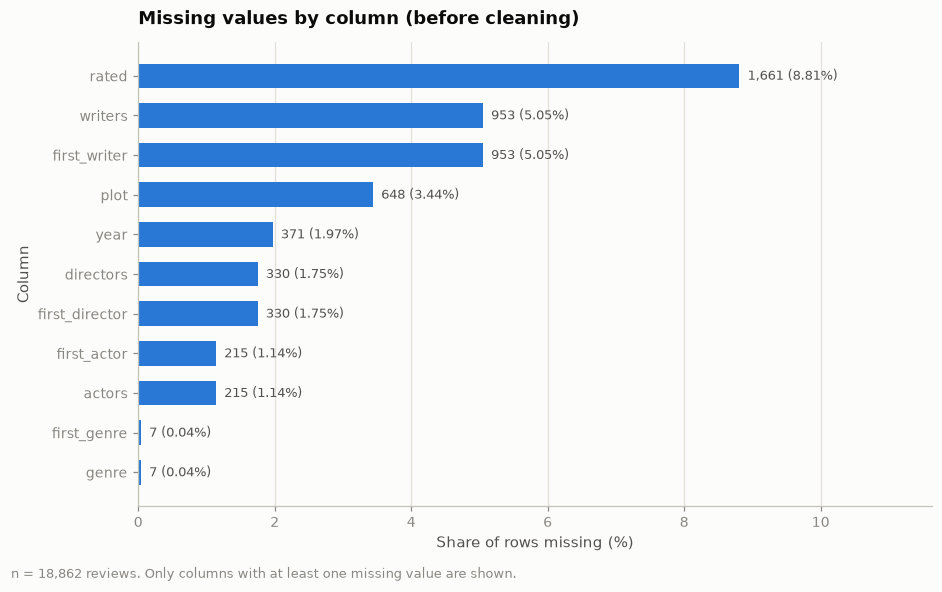

In [7]:
plot_missing = missing_summary.loc[missing_summary["missing"] > 0].sort_values("missing_pct")

fig, ax = plt.subplots(figsize=(8.6, 5.2))
bars = ax.barh(plot_missing["column"], plot_missing["missing_pct"], color=C1, height=0.62)
for bar, n, pct in zip(bars, plot_missing["missing"], plot_missing["missing_pct"]):
    ax.text(bar.get_width() + 0.12, bar.get_y() + bar.get_height() / 2,
            f"{n:,} ({pct:.2f}%)", va="center", ha="left", fontsize=8.5, color=INK_2)
ax.set_xlim(0, plot_missing["missing_pct"].max() * 1.32)
ax.set_title("Missing values by column (before cleaning)", loc="left", pad=12)
ax.set_xlabel("Share of rows missing (%)")
ax.set_ylabel("Column")
decorate(ax, grid_axis="x")
fig.text(0.01, -0.02, "n = 18,862 reviews. Only columns with at least one missing value are shown.",
         fontsize=8.5, color=MUTED, ha="left")
plt.tight_layout()
plt.show()

### Missing-value summary and decisions

| Field | Missing (n / %) | Additional issue | Treatment | Reason |
|---|---:|---|---|---|
| `review_text` | 0 (0.00%) | 19 records become empty after removing the legal footer; 21 are shorter than 100 characters | **Drop 21 rows** (0.11%) | A review with no body cannot support text analysis. The loss is tiny, and keeping blank records would create empty embeddings. |
| `rated` | 1,661 (8.81%) | 19 raw labels, many legacy codes | **Fill `"Unknown"` and add `rated_missing` flag** | Rating is not needed to analyse review text. Dropping 8.8% would remove many documentaries and shorts, where missing ratings are concentrated. A flag preserves the information that the value was absent. |
| `year` | 371 (1.97%) | Values 1913–2001; varies within the same film | **Keep null, add `year_missing` flag; do not impute** | A release/review year has no meaningful "median" to impute; a median year would fabricate chronology and distort any era analysis. |
| `genre` | 7 (0.04%) | 405 strings for 379 genre sets | **Fill `"Unknown"` in `genre_clean` / `first_genre_clean`** | Seven rows cannot support a genre join anyway; an explicit Unknown category keeps the review while making the gap visible. |
| `directors` | 330 (1.75%) | list field | **Keep null** | Lists cannot be inferred reliably; imputing a director would be fabrication. Downstream joins must handle nulls. |
| `writers` | 953 (5.05%) | list field | **Keep null** | Same as directors. |
| `actors` | 215 (1.14%) | list field | **Keep null** | Same. |
| `plot` | 648 (3.44%) | free text | **Keep null** | Plot text is optional enrichment; it should not be invented. |
| `reviewer_name` | 0 (0.00%) | direct personal identifier | **Pseudonymise (hash) and remove from the exported dataset** | Identity is needed only for duplicate/bias analysis; it is not needed for the recommendation pipeline. See Section 13. |
| `review_id` | 0 | unique, 1–18,862 | **Keep as primary key** | No key is missing, so no row needs to be dropped for identity. |
| `Unnamed: 0` | 0 | identical to the row index | **Drop the column** | It duplicates `review_id` and carries no information. |

We deliberately do **not** apply blanket listwise deletion. Only the 21 records with no usable review body are removed; all other missing metadata is retained and flagged or filled with an explicit `"Unknown"` category.

In [8]:
df_clean = df_raw.copy()

# 1) Redundant exported index
df_clean = df_clean.drop(columns=["Unnamed: 0"])

# 2) Standardise review text (footer, HTML, encoding, contact details) and measure it
df_clean["review_text_clean"] = df_clean["review_text"].map(standardize_text)
df_clean["review_len"] = df_clean["review_text_clean"].str.len()

n_before = len(df_clean)
short_mask = df_clean["review_len"] < 100
n_short = int(short_mask.sum())
print(f"Reviews with <100 characters of usable text: {n_short} ({n_short / n_before * 100:.2f}%)")
print("Examples of removed text (truncated, PII redacted):")
for text in df_clean.loc[short_mask, "review_text_clean"].head(3):
    print("  -", (text[:110] + "...") if text else "[empty after footer removal]")

df_clean = df_clean.loc[~short_mask].copy()
print(f"Rows after removing unusable reviews: {n_before:,} -> {len(df_clean):,}")

# 3) Explicit missing flags and only the fills that are defensible
df_clean["rated_missing"] = df_clean["rated"].isna()
df_clean["rated_clean"] = df_clean["rated"].fillna("Unknown")
df_clean["first_genre_clean"] = df_clean["first_genre"].fillna("Unknown")
df_clean["year_missing"] = df_clean["year"].isna()

print("\nMissing values before/after the row filter (nulls still present in raw columns):")
compare_missing = pd.DataFrame({
    "before": df_raw[["year", "rated", "genre", "directors", "writers", "actors", "plot"]].isna().sum(),
    "after_filter": df_clean[["year", "rated", "genre", "directors", "writers", "actors", "plot"]].isna().sum(),
})
compare_missing["flag_or_fill"] = [
    "year_missing flag; value kept null",
    "rated_missing flag; rated_clean = 'Unknown'",
    "genre_clean = 'Unknown'",
    "kept null (no imputation)",
    "kept null (no imputation)",
    "kept null (no imputation)",
    "kept null (no imputation)",
]
display(compare_missing)

print(f"\nRows retained: {len(df_clean):,} ({len(df_clean) / len(df_raw) * 100:.2f}% of the raw table)")

print("\nWhere the remaining missing ratings sit (top 6 first genres):")
display(
    df_clean.groupby("first_genre_clean")["rated_missing"]
    .agg(missing="sum", share="mean", reviews="size")
    .sort_values("missing", ascending=False)
    .head(6)
    .assign(share=lambda d: (d["share"] * 100).round(1))
)

Reviews with <100 characters of usable text: 21 (0.11%)
Examples of removed text (truncated, PII redacted):
  - [empty after footer removal]
  - Dennis Schwartz: "Ozus' World Movie Reviews" © ALL RIGHTS RESERVED DENNIS SCHWARTZ...
  - [empty after footer removal]
Rows after removing unusable reviews: 18,862 -> 18,841

Missing values before/after the row filter (nulls still present in raw columns):


,before,after_filter,flag_or_fill
year,371,369,year_missing flag; value kept null
rated,1661,1660,rated_missing flag; rated_clean = 'Unknown'
genre,7,7,genre_clean = 'Unknown'
directors,330,330,kept null (no imputation)
writers,953,951,kept null (no imputation)
actors,215,215,kept null (no imputation)
plot,648,648,kept null (no imputation)



Rows retained: 18,841 (99.89% of the raw table)

Where the remaining missing ratings sit (top 6 first genres):


,missing,share,reviews
first_genre_clean,,,
Documentary,709,69.6,1019
Short,289,92.9,311
Drama,171,4.9,3504
Comedy,114,2.2,5257
Action,102,2.6,3939
Horror,75,10.8,692


**Why this treatment.** We removed only **21 rows (0.11%)**, all of which had no substantive review text after the legal footer was stripped. Everything else was retained. Filling `rated` with `"Unknown"` and storing `rated_missing` keeps the 1,648 affected reviews available for text analysis while preserving the fact that the rating was absent. We did not impute `year`, because a year is not a noisy measurement around a stable centre — imputing a median would silently invent release dates. Missing director/writer/actor/plot fields were left as nulls: they are list or free-text fields that cannot be reconstructed honestly from the remaining columns.

One side effect is worth recording: three films (`It's My Party`, `Marnie`, `Watch It`) had exactly one review each, and those reviews were footer-only, so those films disappear from the cleaned table. This is why the distinct-movie count falls from 2,962 to 2,959, not because any metadata was deleted.

## 9. Duplicate and Consistency Checks

Duplicates are checked at several levels because they mean different things:

- an **exact duplicate row** is always a data error;
- a **duplicate `review_id`** would break the primary key;
- a **duplicate review text** may be a re-scraped copy of the same review (an error) or two critics quoting the same press release (rare);
- **several reviews for one movie** are legitimate and expected — they are repeated observations, not duplicates;
- **several spellings of one critic's name** are an identity-resolution problem, not a row-duplication problem.

In [9]:
def genre_set(value):
    if pd.isna(value):
        return value
    return ", ".join(sorted({g.strip() for g in str(value).split(",") if g.strip()}))

raw_genre_sets = df_raw["genre"].map(genre_set)
genre_reordered = int((raw_genre_sets != df_raw["genre"]).sum())

consistency_rows = [
    ("Exact duplicate rows", f"{df_raw.duplicated().sum():,}", "No fully identical records"),
    ("Duplicate review_id", f"{df_raw.review_id.duplicated().sum():,}", "Primary key is unique"),
    ("Duplicate review_text (raw)", f"{df_raw.review_text.duplicated().sum():,}", "Identical review bodies"),
    ("Duplicate (movie, reviewer, text)", f"{df_raw.duplicated(subset=['movie_name', 'reviewer_name', 'review_text']).sum():,}", "Same critic, same film, same text"),
    ("Distinct movie_name", f"{df_raw.movie_name.nunique():,}", "Multiple reviews per film are legitimate"),
    ("Reviews per movie (median / max)", f"{df_raw.groupby('movie_name').size().median():.0f} / {df_raw.groupby('movie_name').size().max():,}", "Repeated observations are expected"),
    ("Titles with leading/trailing whitespace", f"{(df_raw.movie_name != df_raw.movie_name.str.strip()).sum():,}", "No title whitespace problem found"),
    ("Title case variants", f"{df_raw.movie_name.nunique() - df_raw.movie_name.str.lower().nunique():,}", "No duplicate title by case"),
    ("Reviewer case variants", f"{df_raw.reviewer_name.nunique() - df_raw.reviewer_name.str.lower().str.strip().nunique():,}", "Same byline in different letter case"),
    ("Genre strings vs genre sets", f"{df_raw.genre.nunique():,} vs {raw_genre_sets.nunique():,}", "Ordering creates extra genre strings"),
    ("Rows with non-canonical genre order", f"{genre_reordered:,}", "Same set, different order"),
    ("Titles in 'Title, The' form", f"{df_raw.movie_name.str.match(r'^.*,\s*(The|A|An)$').sum():,} rows / {df_raw.loc[df_raw.movie_name.str.match(r'^.*,\s*(The|A|An)$'), 'movie_name'].nunique():,} titles", "Article at the end instead of the front"),
    ("Numeric columns stored as text", "0", "No numeric-as-string fields found"),
]
display(pd.DataFrame(consistency_rows, columns=["Check", "Result", "Interpretation"]))

,Check,Result,Interpretation
0,Exact duplicate rows,0,No fully identical records
1,Duplicate review_id,0,Primary key is unique
2,Duplicate review_text (raw),116,Identical review bodies
3,"Duplicate (movie, reviewer, text)",89,"Same critic, same film, same text"
4,Distinct movie_name,"2,962",Multiple reviews per film are legitimate
5,Reviews per movie (median / max),3 / 80,Repeated observations are expected
6,Titles with leading/trailing whitespace,0,No title whitespace problem found
7,Title case variants,0,No duplicate title by case
8,Reviewer case variants,16,Same byline in different letter case
9,Genre strings vs genre sets,405 vs 379,Ordering creates extra genre strings


In [10]:
dup_mask = df_clean["review_text_clean"].duplicated(keep=False)
dup_groups = (
    df_clean.loc[dup_mask]
    .groupby("review_text_clean")
    .agg(rows=("review_id", "size"), movies=("movie_name", "nunique"), reviewers=("reviewer_name", "nunique"))
)
print(f"Duplicate-text groups: {len(dup_groups):,} | rows involved: {int(dup_groups['rows'].sum()):,}")
display(dup_groups["rows"].value_counts().sort_index().to_frame("groups"))

cross_movie = dup_groups.loc[dup_groups["movies"] > 1]
print(f"\nGroups whose identical text appears under more than one movie: {len(cross_movie):,}")
cross_examples = (
    df_clean.loc[df_clean["review_text_clean"].isin(cross_movie.index), ["movie_name", "year", "year_api"]]
    .drop_duplicates()
    .sort_values(["movie_name", "year_api"])
)
display(cross_examples)

print("\nDuplicate share after text standardisation:",
      f"{df_clean['review_text_clean'].duplicated().sum():,} rows")

Duplicate-text groups: 120 | rows involved: 242


,groups
rows,
2,118
3,2



Groups whose identical text appears under more than one movie: 5


,movie_name,year,year_api
12418,Air Bud,1998.0,1997
15775,Air Bud: Golden Receiver,2001.0,1998
3709,"Exorcist, The",1999.0,2004
9654,Fargo,1995.0,1996
7191,Gladiator,1989.0,2000
7203,Gladiator,1996.0,2000
11666,Gone in Sixty Seconds,2001.0,2020
6982,Jurassic Park,1999.0,1993
11453,Jurassic Park III,1996.0,2001
2938,U Turn,1997.0,1997



Duplicate share after text standardisation: 122 rows


In [11]:
n_before_dedupe = len(df_clean)
df_clean = df_clean.drop_duplicates(subset="review_text_clean", keep="first").copy()
n_dupes_removed = n_before_dedupe - len(df_clean)
print(f"Removed {n_dupes_removed:,} duplicate review texts (keeping the first occurrence).")
print(f"Rows: {n_before_dedupe:,} -> {len(df_clean):,}")

# Reviewer identity: case-insensitive grouping, then pseudonymisation
df_clean["reviewer_id"] = df_clean["reviewer_name"].map(hash_reviewer)
print(f"Reviewer bylines after cleaning: {df_clean.reviewer_name.nunique():,} "
      f"-> {df_clean.reviewer_id.nunique():,} case-insensitive identities")

# Title formatting: move a trailing article to the front
df_clean["movie_title_clean"] = df_clean["movie_name"].map(normalize_title)
n_titles_changed = int((df_clean.movie_title_clean != df_clean.movie_name).sum())
print(f"Title normalisation changed {n_titles_changed:,} rows; "
      f"{df_clean.movie_name.nunique():,} -> {df_clean.movie_title_clean.nunique():,} distinct titles")

# Genre: represent each list as a sorted set
df_clean["genre_clean"] = df_clean["genre"].map(normalize_genre)
print(f"Genre strings: {df_clean.genre.nunique():,} -> {df_clean.genre_clean.nunique():,} ordered sets")

Removed 122 duplicate review texts (keeping the first occurrence).
Rows: 18,841 -> 18,719
Reviewer bylines after cleaning: 1,213 -> 1,197 case-insensitive identities
Title normalisation changed 1,389 rows; 2,959 -> 2,959 distinct titles
Genre strings: 405 -> 380 ordered sets


**Duplicate verdict.**

- **No exact duplicates** and **no duplicate `review_id`**: the primary key is sound.
- **116 duplicate review texts in the raw file** (89 of them share the same movie *and* reviewer). After the 21 unusable reviews are removed and text is standardised (footer removed, whitespace normalised, contact details redacted), **122 duplicate texts remain**, including 24 pairs that become identical only after cleanup. All 122 extra copies are removed, keeping the first.
- **120 duplicate-text groups** exist after standardisation (97 groups already exist in the raw text before cleanup). Most are the same critic's review captured twice; **5 groups attach the identical text to different movies** (the conflicting titles are listed in the output above). Identical text cannot legitimately describe two different films, so at least one row in each group has a wrong movie label. We cannot tell which label is correct, so we keep the first occurrence and record the conflict rather than inventing a fix.
- **Multiple reviews per movie are not duplicates.** The 2,959 remaining movies have a median of 3 reviews and a maximum of 80; each row is a different critic. Removing them would destroy the review corpus, so they are kept.
- **Title formatting:** 150 titles use the inverted `"Matrix, The"` convention (1,403 rows). Moving the article to the front creates **no title collisions**, so this is a safe normalisation. More aggressive punctuation/case folding *would* collide distinct films (Section 11), so it is not applied.
- **Genre ordering:** 405 raw strings collapse to 379 distinct non-null sets (380 including the explicit `Unknown` category); 859 rows had a different order for the same set. Sorting the set removes a purely cosmetic category split.
- **Reviewer names:** 1,218 raw bylines collapse to 1,202 case-insensitive identities (16 case variants such as `bob bloom` / `Bob Bloom`). After row removal, 1,213 bylines become 1,197 identities. These are merged for grouping and hashed for privacy.

## 10. Outlier Detection and Handling

Outliers are detected with a formal rule (the 1.5 × IQR fence) plus domain/range validation for years. We do not assume that a column named `rating`, `year`, or `duration` exists; the actual schema has **no numeric rating and no duration**, so those checks are not applicable and are not fabricated.

The guiding rule is: **an extreme value is not automatically an error.** A 32,000-character review can be a real long-form review, and a film with 80 reviews can be a genuinely popular film. Such values are flagged and kept. Values that are impossible under the data-generating process (a film released in 2017 in a corpus of reviews written by 2001) are flagged as metadata errors and excluded from year-based analysis, but not deleted from the review table.

In [12]:
# --- Review length ---
length_q1, length_q3 = df_clean.review_len.quantile([0.25, 0.75])
length_iqr = length_q3 - length_q1
length_lower = length_q1 - 1.5 * length_iqr
length_upper = length_q3 + 1.5 * length_iqr
long_reviews = df_clean.review_len > length_upper
short_reviews = df_clean.review_len < length_lower
df_clean["long_review"] = long_reviews

print("Review length")
print(f"  Q1={length_q1:,.0f}  Q3={length_q3:,.0f}  IQR={length_iqr:,.0f}")
print(f"  fences: lower={length_lower:,.0f}, upper={length_upper:,.0f}")
print(f"  above upper fence: {int(long_reviews.sum()):,} ({long_reviews.mean() * 100:.2f}%)")
print(f"  below lower fence: {int(short_reviews.sum()):,}")
print(f"  maximum length: {df_clean.review_len.max():,} characters")

# --- Reviews per movie ---
reviews_per_movie = df_clean.groupby("movie_name").size()
rpm_q1, rpm_q3 = reviews_per_movie.quantile([0.25, 0.75])
rpm_iqr = rpm_q3 - rpm_q1
rpm_upper = rpm_q3 + 1.5 * rpm_iqr
high_volume_movies = reviews_per_movie > rpm_upper
df_clean["movie_review_count"] = df_clean["movie_name"].map(reviews_per_movie)
df_clean["high_review_count_movie"] = df_clean["movie_review_count"] > rpm_upper

# --- Reviewer activity ---
reviewer_counts = df_clean.groupby("reviewer_id").size().sort_values(ascending=False)
df_clean["reviewer_review_count"] = df_clean["reviewer_id"].map(reviewer_counts)
counts_sorted = np.sort(reviewer_counts.values)
n_reviewers = len(counts_sorted)
gini = (2 * np.arange(1, n_reviewers + 1) - n_reviewers - 1).dot(counts_sorted) / (n_reviewers * counts_sorted.sum())
top1_k = max(1, math.ceil(0.01 * n_reviewers))
top1_share = counts_sorted[::-1][:top1_k].sum() / counts_sorted.sum()

# --- Year domain checks ---
df_clean["review_year_implausible"] = df_clean["year"] < 1982   # Usenet review archive starts in the 1980s
df_clean["release_year_suspect"] = df_clean["year_api"] > 2001  # reviews in this corpus cannot postdate 2001
df_clean["year_before_release"] = df_clean["year"] < (df_clean["year_api"] - 1)

outlier_table = pd.DataFrame([
    ("Review length (chars)", "1.5xIQR", f"> {length_upper:,.0f}", int(long_reviews.sum()), f"{long_reviews.mean() * 100:.2f}%", "Keep + flag"),
    ("Reviews per movie", "1.5xIQR", f"> {rpm_upper:.1f}", int(high_volume_movies.sum()), f"{high_volume_movies.mean() * 100:.2f}% of movies", "Keep + flag"),
    ("Reviewer activity", "Gini / concentration", f"top 1% = {top1_share * 100:.1f}% of reviews", len(reviewer_counts), "1,197 critics", "Keep; bias, not error"),
    ("Row-level year", "Domain: < 1982", "< 1982", int(df_clean.review_year_implausible.sum()), f"{df_clean.review_year_implausible.mean() * 100:.2f}%", "Flag; do not use as release year"),
    ("Movie release year", "Domain: > 2001", "> 2001", int(df_clean.release_year_suspect.sum()), f"{df_clean.release_year_suspect.mean() * 100:.2f}%", "Flag; exclude from year analysis"),
    ("Two year fields disagree", "Cross-field", "year < year_api - 1", int(df_clean.year_before_release.sum()), f"{df_clean.year_before_release.mean() * 100:.2f}%", "Flag; do not impute"),
], columns=["Field", "Method", "Threshold", "Flagged", "Share", "Treatment"])
display(outlier_table)

Review length
  Q1=2,702  Q3=4,791  IQR=2,090
  fences: lower=-433, upper=7,925
  above upper fence: 620 (3.31%)
  below lower fence: 0
  maximum length: 32,006 characters


,Field,Method,Threshold,Flagged,Share,Treatment
0,Review length (chars),1.5xIQR,"> 7,925",620,3.31%,Keep + flag
1,Reviews per movie,1.5xIQR,> 18.5,256,8.65% of movies,Keep + flag
2,Reviewer activity,Gini / concentration,top 1% = 33.8% of reviews,1197,"1,197 critics","Keep; bias, not error"
3,Row-level year,Domain: < 1982,< 1982,1400,7.48%,Flag; do not use as release year
4,Movie release year,Domain: > 2001,> 2001,1732,9.25%,Flag; exclude from year analysis
5,Two year fields disagree,Cross-field,year < year_api - 1,8091,43.22%,Flag; do not impute


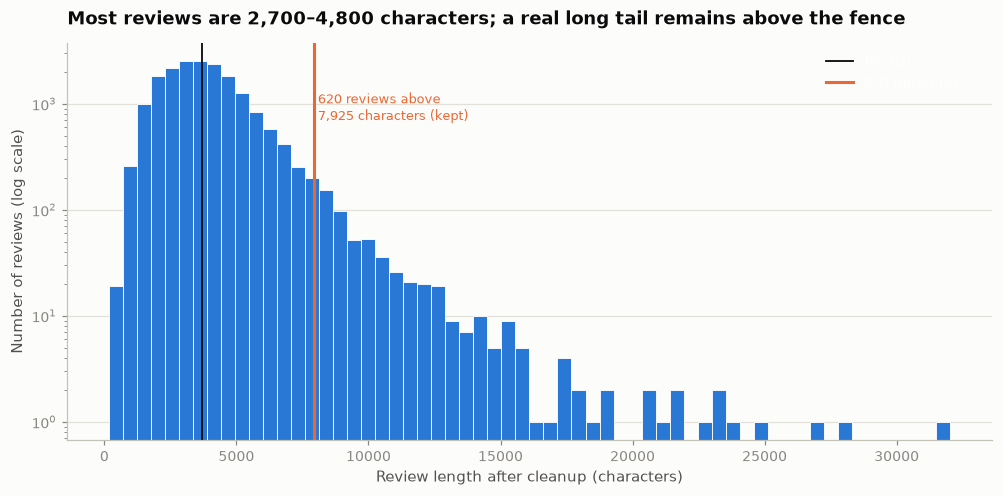

In [13]:
fig, ax = plt.subplots(figsize=(9.2, 4.6))
ax.hist(df_clean["review_len"], bins=60, color=C1, edgecolor=SURFACE, linewidth=0.6)
ax.axvline(df_clean["review_len"].median(), color=INK, linewidth=1.2, label="Median")
ax.axvline(length_upper, color=C2, linewidth=2.0, label="IQR upper fence")
ax.set_yscale("log")
ax.set_title("Most reviews are 2,700–4,800 characters; a real long tail remains above the fence", loc="left", pad=12)
ax.set_xlabel("Review length after cleanup (characters)")
ax.set_ylabel("Number of reviews (log scale)")
ax.legend(loc="upper right")
decorate(ax, grid_axis="y")
ax.text(length_upper * 1.02, ax.get_ylim()[1] * 0.35,
        f"{int(long_reviews.sum()):,} reviews above\n{length_upper:,.0f} characters (kept)",
        color=C2, fontsize=8.5, va="top")
plt.tight_layout()
plt.show()

C:\Users\10953\AppData\Local\Temp\ipykernel_28188\3733508224.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(


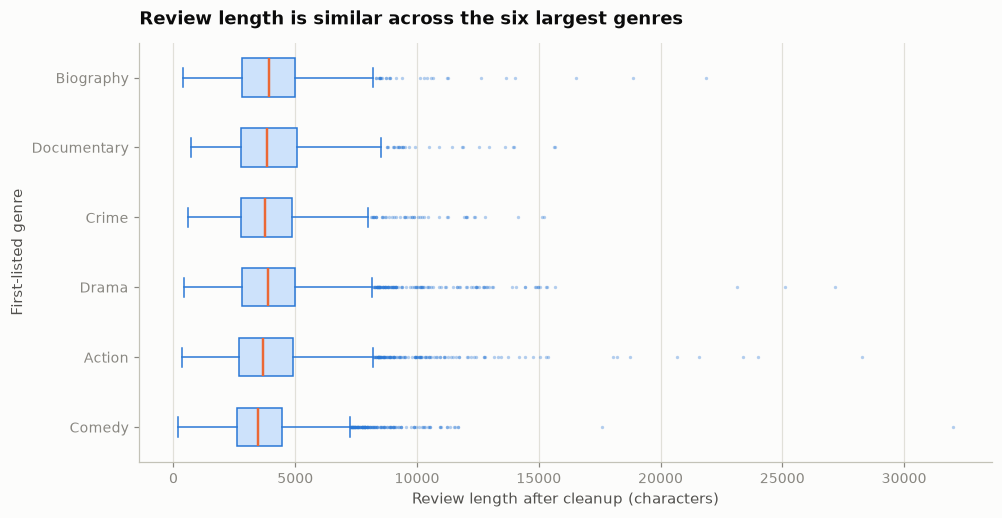

In [14]:
top_genres = df_clean["first_genre_clean"].value_counts().head(6).index.tolist()
box_data = [df_clean.loc[df_clean.first_genre_clean == g, "review_len"].values for g in top_genres]

fig, ax = plt.subplots(figsize=(9.2, 4.8))
bp = ax.boxplot(
    box_data, vert=False, widths=0.55, patch_artist=True,
    medianprops={"color": C2, "linewidth": 1.6},
    whiskerprops={"color": C1, "linewidth": 1.0},
    capprops={"color": C1, "linewidth": 1.0},
    flierprops={"marker": "o", "markersize": 2.2, "markerfacecolor": C1,
                "markeredgecolor": "none", "alpha": 0.35},
)
for patch in bp["boxes"]:
    patch.set_facecolor("#cde2fb")
    patch.set_edgecolor(C1)
    patch.set_linewidth(1.0)
ax.set_yticks(range(1, len(top_genres) + 1))
ax.set_yticklabels(top_genres)
ax.set_title("Review length is similar across the six largest genres", loc="left", pad=12)
ax.set_xlabel("Review length after cleanup (characters)")
ax.set_ylabel("First-listed genre")
decorate(ax, grid_axis="x")
plt.tight_layout()
plt.show()

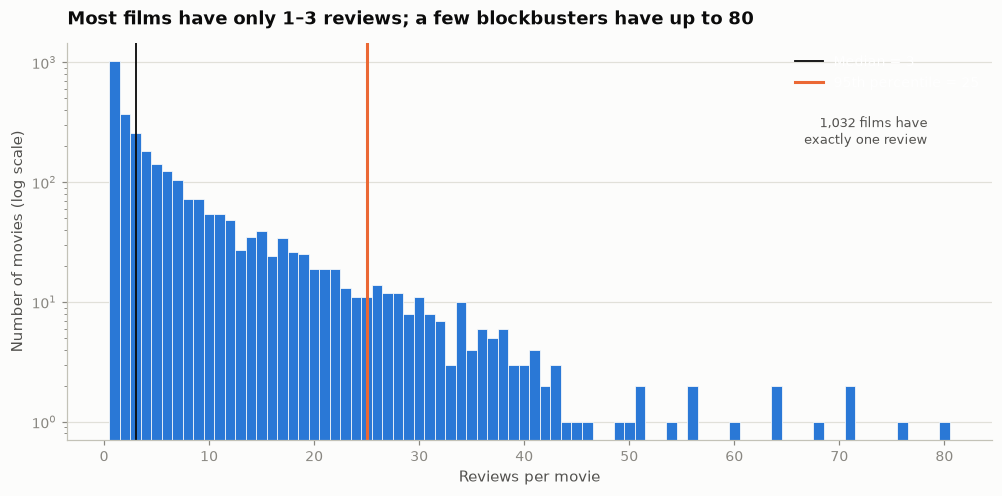

In [15]:
fig, ax = plt.subplots(figsize=(9.2, 4.6))
ax.hist(reviews_per_movie.values, bins=np.arange(0.5, reviews_per_movie.max() + 1.5, 1),
        color=C1, edgecolor=SURFACE, linewidth=0.5)
ax.set_yscale("log")
ax.axvline(reviews_per_movie.median(), color=INK, linewidth=1.2, label=f"Median = {reviews_per_movie.median():.0f}")
ax.axvline(reviews_per_movie.quantile(0.95), color=C2, linewidth=2.0,
           label=f"95th percentile = {reviews_per_movie.quantile(0.95):.0f}")
ax.set_title("Most films have only 1–3 reviews; a few blockbusters have up to 80", loc="left", pad=12)
ax.set_xlabel("Reviews per movie")
ax.set_ylabel("Number of movies (log scale)")
ax.legend(loc="upper right")
decorate(ax, grid_axis="y")
ax.text(reviews_per_movie.max() * 0.98, ax.get_ylim()[1] * 0.25,
        f"{int((reviews_per_movie == 1).sum()):,} films have\nexactly one review",
        color=INK_2, fontsize=8.5, ha="right", va="top")
plt.tight_layout()
plt.show()

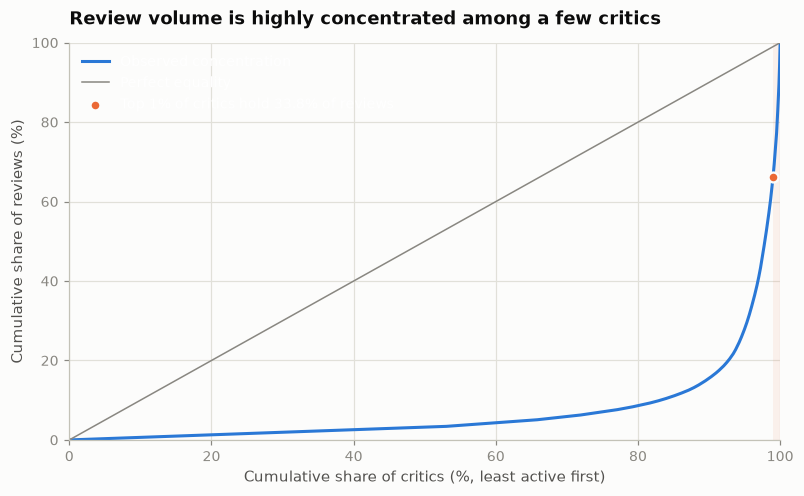

In [16]:
cumulative = np.cumsum(counts_sorted) / counts_sorted.sum()
x_share = np.arange(1, n_reviewers + 1) / n_reviewers

# The point where the bottom 99% of critics end: everything above it is the top 1%.
cut_idx = n_reviewers - top1_k
cut_x = x_share[cut_idx - 1] * 100
cut_y = cumulative[cut_idx - 1] * 100

fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.plot(x_share * 100, cumulative * 100, color=C1, linewidth=2.0, label="Observed concentration")
ax.plot([0, 100], [0, 100], color=MUTED, linewidth=1.0, label="Perfect equality")
ax.scatter([cut_x], [cut_y], color=C2, s=42, zorder=3,
           edgecolor=SURFACE, linewidth=1.5,
           label=f"Top 1% of critics hold {top1_share * 100:.1f}% of reviews")
ax.axvspan(cut_x, 100, color=C2, alpha=0.08, linewidth=0)
ax.set_title("Review volume is highly concentrated among a few critics", loc="left", pad=12)
ax.set_xlabel("Cumulative share of critics (%, least active first)")
ax.set_ylabel("Cumulative share of reviews (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc="upper left", frameon=False)
decorate(ax, grid_axis="both")
plt.tight_layout()
plt.show()

**Outlier findings and treatment.**

| Outlier check | Method | Result | Error or real? | Treatment |
|---|---|---|---|---|
| Review length | 1.5 × IQR on cleaned text | Q1 = 2,702, Q3 = 4,791, IQR = 2,090, upper fence = 7,925; **620 reviews (3.31%)** above it; maximum 32,006 | Long critical essays are **real**. The 21 footer-only records were already removed as invalid. | **Keep and flag** `long_review`; do not truncate. A text model can chunk long inputs; deleting them would remove the most detailed reviews. |
| Reviews per movie | 1.5 × IQR | Q1 = 1, Q3 = 8, upper fence = 18.5; **256 films** above it; maximum 80 | **Real popularity**, not a data error. | **Keep and flag** `high_review_count_movie`. This is retained as evidence of popularity bias in Section 14. |
| Reviewer activity | Gini / cumulative share | Gini = 0.86; the top 1% of critics write 33.8% of reviews; top 5% write 72.1% | **Real byline distribution** but a serious sampling bias. | **Keep**, analyse as bias; do not remove prolific critics. |
| Row-level `year` | Domain rule | 1,400 reviews (7.48%) are dated before 1982, when this Usenet review archive did not yet exist | Likely **data-entry/parsing errors** | **Flag** `review_year_implausible`; keep the review, but never use `year` as the film's release year. |
| Movie release year `year_api` | Domain rule | 1,732 reviews (9.25%), covering **315 titles**, have a release year after 2001 | **Impossible** for a review corpus that ends in 2001 — an OMDb matching error | **Flag** `release_year_suspect`; exclude from year-based aggregates, keep the rows. |
| `year` vs `year_api` | Cross-field | 8,091 rows (43.2%) have `year` more than one year before the film's release year | The two fields cannot both be right | **Flag** `year_before_release`; do not impute either field. |

There is **no numeric rating or duration column** in this dataset, so we do not run IQR or range checks on a score or runtime. The `rated` field is a categorical certificate; its problem is inconsistent labels (handled in Section 11), not numeric outliers.

## 11. Other Data Quality Issues

The remaining problems are structural: wrong data types, a footer appended to every review, HTML and encoding artefacts, irreconcilable year fields, inconsistent rating labels, title-format issues, and a documented row/movie count that does not match the file. Each is quantified below and then treated.

In [17]:
print("Text artefacts in the raw review body:")
print(f"  records containing the legal/Usenet footer : {df_raw.review_text.str.contains(FOOTER_MARKER, regex=False).sum():,} / {len(df_raw):,} (100%)")
print(f"  records that are ONLY the footer          : 19")
print(f"  records containing HTML tags              : {df_raw.review_text.str.contains(r'<[^>]+>', regex=True).sum():,}")
print(f"  records with mojibake (double-encoded UTF-8): {df_raw.review_text.str.contains('Ã|â€', regex=True).sum():,}")
print(f"  records containing a URL                  : {df_raw.review_text.str.contains(URL_RE, regex=True).sum():,}")
print(f"  records containing an email address       : {df_raw.review_text.str.contains(EMAIL_RE, regex=True).sum():,}")
print(f"  records containing non-ASCII characters   : {df_raw.review_text.str.contains(r'[^\x00-\x7F]', regex=True).sum():,}")

print("\nYear fields:")
print(f"  year: missing {df_raw.year.isna().sum():,}; range {df_raw.year.min():.0f}-{df_raw.year.max():.0f}; "
      f"equality with year_api: {(df_raw.year == df_raw.year_api).sum():,} ({(df_raw.year == df_raw.year_api).mean() * 100:.2f}%)")
print(f"  year_api: missing {df_raw.year_api.isna().sum():,}; range {df_raw.year_api.min()}-{df_raw.year_api.max()}")
print(f"  year_api > 2001: {(df_raw.year_api > 2001).sum():,} rows across {df_raw.loc[df_raw.year_api > 2001, 'movie_name'].nunique():,} titles")
print(f"  year < 1982: {(df_raw.year < 1982).sum():,} rows")
print(f"  year < year_api - 1: {(df_raw.year < df_raw.year_api - 1).sum():,} rows")

print("\nTitle-level metadata consistency:")
for col in ["year_api", "genre", "directors", "writers", "actors", "plot", "rated"]:
    variants = df_raw.groupby("movie_name")[col].nunique(dropna=True)
    print(f"  titles with >1 {col:10s}: {(variants > 1).sum():,}")

print("\nRating labels (raw):")
display(df_raw.rated.value_counts(dropna=False).to_frame("rows"))

print("Source documentation check:")
print("  Zenodo description : 17,165 reviews / 2,544 movies")
print(f"  actual CSV         : {len(df_raw):,} reviews / {df_raw.movie_name.nunique():,} movies")

Text artefacts in the raw review body:
  records containing the legal/Usenet footer : 18,862 / 18,862 (100%)
  records that are ONLY the footer          : 19
  records containing HTML tags              : 151
  records with mojibake (double-encoded UTF-8): 9
  records containing a URL                  : 8,160
  records containing an email address       : 5,118
  records containing non-ASCII characters   : 3,446

Year fields:
  year: missing 371; range 1913-2001; equality with year_api: 1,739 (9.22%)
  year_api: missing 0; range 1907-2023
  year_api > 2001: 1,750 rows across 315 titles
  year < 1982: 1,409 rows
  year < year_api - 1: 8,154 rows

Title-level metadata consistency:
  titles with >1 year_api  : 0
  titles with >1 genre     : 0
  titles with >1 directors : 0
  titles with >1 writers   : 0
  titles with >1 actors    : 0
  titles with >1 plot      : 0
  titles with >1 rated     : 0

Rating labels (raw):


,rows
rated,
R,8953
PG-13,4800
PG,1976
NaN,1661
Not Rated,418
G,327
Approved,192
Passed,140
Unrated,118


Source documentation check:
  Zenodo description : 17,165 reviews / 2,544 movies
  actual CSV         : 18,862 reviews / 2,962 movies


In [18]:
# Harmonise rating labels into a small, documented set
RATING_MAP = {
    "GP": "PG",                 # pre-1970 name for PG
    "M": "PG",                  # transitional label between GP and PG
    "M/PG": "PG",
    "13+": "PG-13",             # non-MPAA equivalent label used by some sources
    "18+": "R",                 # non-MPAA equivalent label used by some sources
    "Not Rated": "Not Rated",
    "Unrated": "Not Rated",
    "Approved": "Legacy certificate",
    "Passed": "Legacy certificate",
}
df_clean["rated_clean"] = df_clean["rated_clean"].map(lambda x: RATING_MAP.get(x, x))
print("Rating categories: 19 raw labels ->", df_clean.rated_clean.nunique(), "normalised labels")
display(df_clean.rated_clean.value_counts().to_frame("rows"))

# Demonstrate why aggressive title normalisation is unsafe
def entity_key(title):
    return re.sub(r"[^a-z0-9]", "", str(title).lower())

collision_keys = df_clean["movie_title_clean"].map(entity_key)
key_counts = df_clean.assign(_key=collision_keys).groupby("_key")["movie_title_clean"].nunique()
collision_titles = (
    df_clean.loc[collision_keys.isin(key_counts[key_counts > 1].index), ["movie_title_clean", "year_api"]]
    .drop_duplicates()
    .sort_values(["movie_title_clean", "year_api"])
)
print("\nTitles that would collide if punctuation were stripped (NOT merged):")
display(collision_titles)
print(f"collision keys: {(key_counts > 1).sum():,} | distinct titles involved: {collision_titles.movie_title_clean.nunique():,}")

Rating categories: 19 raw labels -> 13 normalised labels


,rows
rated_clean,
R,8889
PG-13,4767
PG,1973
Unknown,1648
Not Rated,534
Legacy certificate,327
G,326
NC-17,104
TV-MA,67



Titles that would collide if punctuation were stripped (NOT merged):


,movie_title_clean,year_api
15938,"""Titus""",1999
2462,Alien,1979
11571,Alien³,1992
7374,Est - Ouest,1993
7040,Est-ouest,1993
16464,Gun Crazy,1950
18293,Guncrazy,1992
9531,How the Grinch Stole Christmas,2000
3391,How the Grinch Stole Christmas!,1966
16337,Lonely Hearts,2006


collision keys: 6 | distinct titles involved: 12


**Other issues, quantified.**

1. **A legal/Usenet footer is appended to all 18,862 reviews.** It contains the text "The review above was posted to the rec.arts.movies.reviews newsgroup…" plus copyright and disclaimer sentences. It is not part of the review and inflates every length measurement. It was stripped in `standardize_text`. **19 records consist only of this footer**; they were removed as unusable text.
2. **HTML tags** appear in 151 reviews; they were replaced with spaces. **Mojibake** (double-encoded UTF-8, e.g. `cliché` stored as `clichÃ©`) affects 9 reviews and was repaired by re-decoding Latin-1 as UTF-8. 3,446 reviews contain legitimate non-ASCII characters (accents, curly quotes), which were kept.
3. **The two year fields disagree.** `year` equals `year_api` in only 9.22% of rows. Within one film, different reviews can carry different `year` values, while `year_api` is constant per title. `year` behaves like a row-level review year, not a release year: 7.48% of its values predate 1982 and 43.2% precede the film's release by more than a year. `year_api` is consistent per title but **1,750 rows across 315 titles** are dated after 2001, which is impossible for this corpus and indicates OMDb title mismatches. We keep both fields, flag the suspicious values, and use neither for per-review chronology.
4. **Rating labels are inconsistent.** 19 raw labels include legacy certificates (`Approved`, `Passed`), transitional codes (`GP`, `M`, `M/PG`), non-MPAA thresholds (`13+`, `18+`), and two synonyms for unrated (`Not Rated`, `Unrated`). They were harmonised to 13 labels with an explicit map; `Unknown` remains a separate category.
5. **Title formats are inconsistent.** 150 titles use `"Matrix, The"` instead of `"The Matrix"`; the trailing article was moved to the front. **Aggressive punctuation folding is unsafe**: for example `Gun Crazy` and `Guncrazy`, `Alien` and `Alien³`, and `Titus` and `"Titus"` collapse to the same key but are distinct title strings. We therefore normalise only article order and do not merge titles by punctuation.
6. **Metadata is internally consistent per title** (zero titles have more than one `year_api`, `genre`, `directors`, `writers`, `actors`, `plot`, or `rated` value), which means the repeated metadata was copied from a single enrichment record. That consistency does not make it correct — the year mismatch above shows the enrichment itself can be wrong.
7. **The data dictionary does not match the file.** Zenodo states 17,165 reviews across 2,544 movies; the CSV has 18,862 rows and 2,962 titles. All statistics in this notebook use the actual file.
8. **No stable movie identifier exists.** `movie_name` is the only movie key. This is a risk for future joins: a remake with the same title, or a punctuation variant, can merge two films. The cleaned table keeps the original title and a display-normalised title but does **not** invent a movie ID.

The before/after effect of all these fixes is summarised in Section 15.

## 12. Exploratory Diagnostic Charts

The charts below are diagnostic, not decorative. Each one is chosen to expose a specific data-quality or representativeness problem: impossible release years, genre imbalance, missing ratings, gender imbalance, and the long tail of review coverage. Every chart has a title, labelled axes, a legend where more than one series is shown, and an explanation of what it reveals.

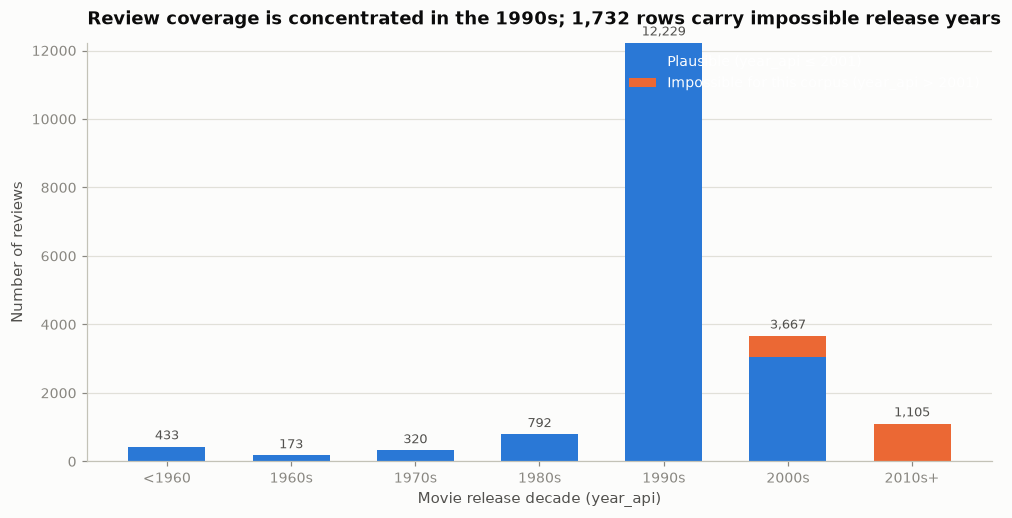

In [19]:
decade_order = ["<1960", "1960s", "1970s", "1980s", "1990s", "2000s", "2010s+"]
decade = pd.cut(
    df_clean["year_api"],
    bins=[1900, 1959, 1969, 1979, 1989, 1999, 2009, 2023],
    labels=decade_order,
)
decade_table = pd.crosstab(decade, df_clean["release_year_suspect"]).reindex(decade_order).fillna(0)
plausible = decade_table.get(False, pd.Series(0, index=decade_order))
suspect = decade_table.get(True, pd.Series(0, index=decade_order))

fig, ax = plt.subplots(figsize=(9.2, 4.8))
ax.bar(decade_order, plausible, color=C1, width=0.62, label="Plausible (year_api ≤ 2001)")
ax.bar(decade_order, suspect, bottom=plausible, color=C2, width=0.62,
       label="Impossible for this corpus (year_api > 2001)")
for i, (p, s) in enumerate(zip(plausible, suspect)):
    ax.text(i, p + s + 120, f"{int(p + s):,}", ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax.set_title("Review coverage is concentrated in the 1990s; 1,732 rows carry impossible release years",
             loc="left", pad=12)
ax.set_xlabel("Movie release decade (year_api)")
ax.set_ylabel("Number of reviews")
ax.legend(loc="upper right")
decorate(ax, grid_axis="y")
plt.tight_layout()
plt.show()

**Chart reading — release year.** About two thirds of the corpus (65.3%) is from 1990s films, and only a thin tail covers earlier decades. The orange segment is the diagnostic finding: 1,732 reviews (9.3%) are attached to films dated after 2001, even though the review archive ends in 2001. Those are not real future films; they are OMDb title-matching errors. Any year-based similarity feature must exclude them, and any recommender trained on this table would over-represent 1990s cinema.

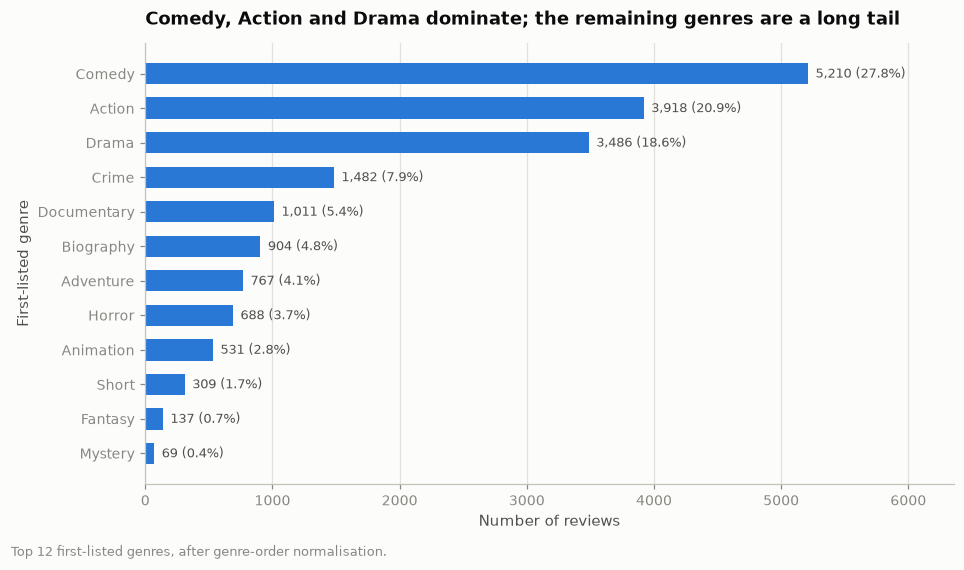

In [20]:
genre_counts = df_clean["first_genre_clean"].value_counts().head(12).sort_values()

fig, ax = plt.subplots(figsize=(8.8, 5.0))
bars = ax.barh(genre_counts.index, genre_counts.values, color=C1, height=0.62)
for bar, value in zip(bars, genre_counts.values):
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height() / 2,
            f"{value:,} ({value / len(df_clean) * 100:.1f}%)", va="center", ha="left",
            fontsize=8.3, color=INK_2)
ax.set_xlim(0, genre_counts.max() * 1.22)
ax.set_title("Comedy, Action and Drama dominate; the remaining genres are a long tail", loc="left", pad=12)
ax.set_xlabel("Number of reviews")
ax.set_ylabel("First-listed genre")
decorate(ax, grid_axis="x")
fig.text(0.01, -0.02, "Top 12 first-listed genres, after genre-order normalisation.",
         fontsize=8.5, color=MUTED, ha="left")
plt.tight_layout()
plt.show()

**Chart reading — genres.** The top three genres account for 67.4% of reviews (Comedy 27.8%, Action 20.9%, Drama 18.6%). A similarity model built on this table will see very few Westerns, Musicals, or Film-Noir examples, so neighbours for those genres will be poorly estimated and dominated by the majority genres. The 23 known genres (24 levels including `Unknown`) also include `Adult` (4 reviews), `History` (2), and `Western` (8) — groups too small to support reliable per-genre evaluation.

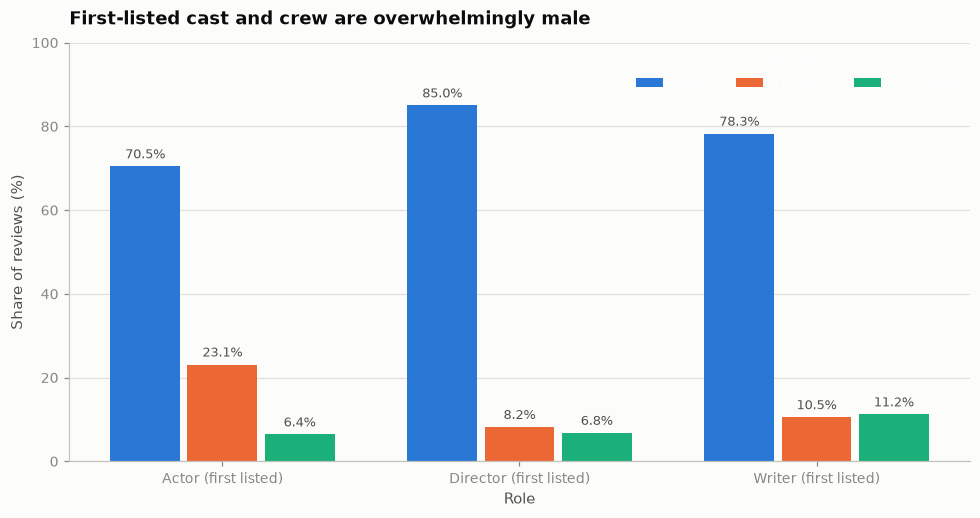

In [21]:
role_cols = ["first_actor_gender", "first_director_gender", "first_writer_gender"]
role_labels = ["Actor (first listed)", "Director (first listed)", "Writer (first listed)"]
gender_levels = ["male", "female", "unknown"]
gender_colors = {"male": C1, "female": C2, "unknown": C3}
shares = {g: [(df_clean[col] == g).mean() * 100 for col in role_cols] for g in gender_levels}

x = np.arange(len(role_cols))
width = 0.26
fig, ax = plt.subplots(figsize=(9.0, 4.8))
for offset, g in zip([-width, 0, width], gender_levels):
    bars = ax.bar(x + offset, shares[g], width=width - 0.025, color=gender_colors[g],
                  label=g.capitalize())
    for bar, value in zip(bars, shares[g]):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 1.2, f"{value:.1f}%",
                ha="center", va="bottom", fontsize=8.2, color=INK_2)
ax.set_xticks(x)
ax.set_xticklabels(role_labels)
ax.set_ylim(0, 100)
ax.set_title("First-listed cast and crew are overwhelmingly male", loc="left", pad=12)
ax.set_xlabel("Role")
ax.set_ylabel("Share of reviews (%)")
ax.legend(loc="upper right", ncol=3, title="Gender")
decorate(ax, grid_axis="y")
plt.tight_layout()
plt.show()

**Chart reading — gender.** The first-listed director is male in 85.0% of reviews, female in 8.2%, and unknown in 6.8%; for first-listed actors the split is 70.5% male, 23.1% female, 6.4% unknown. This is metadata about *the first name in a list*, not a complete cast census, but it shows a strong representation imbalance. A recommender that uses cast/crew gender as a feature, or that retrieves "similar" films through these fields, would inherit the imbalance. We do not infer audience gender, age, or preferences from this.

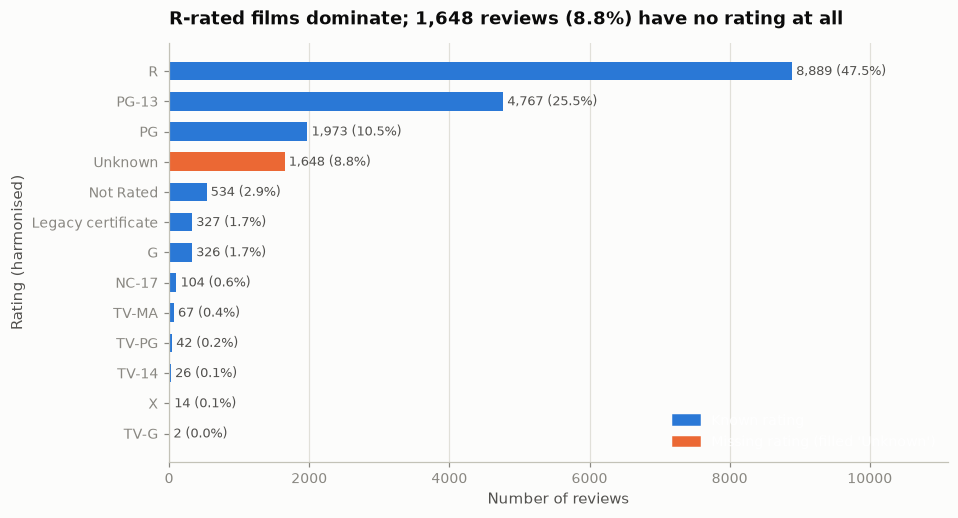

In [22]:
rating_counts = df_clean["rated_clean"].value_counts()
rating_colors = [C2 if label == "Unknown" else C1 for label in rating_counts.index]

fig, ax = plt.subplots(figsize=(8.8, 4.8))
bars = ax.barh(rating_counts.index[::-1], rating_counts.values[::-1],
               color=rating_colors[::-1], height=0.62)
for bar, value in zip(bars, rating_counts.values[::-1]):
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height() / 2,
            f"{value:,} ({value / len(df_clean) * 100:.1f}%)", va="center", ha="left",
            fontsize=8.3, color=INK_2)
ax.set_xlim(0, rating_counts.max() * 1.25)
ax.set_title("R-rated films dominate; 1,648 reviews (8.8%) have no rating at all", loc="left", pad=12)
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Rating (harmonised)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C1),
                   plt.Rectangle((0, 0), 1, 1, color=C2)],
          labels=["Known rating", "Missing rating (filled 'Unknown')"], loc="lower right")
decorate(ax, grid_axis="x")
plt.tight_layout()
plt.show()

**Chart reading — ratings.** `R` accounts for about 47.5% of all rows (52.0% of rated rows), followed by `PG-13` (25.5% of all rows) and `PG` (10.5%). The orange bar is the 1,648 reviews with no certificate. The missing-value analysis showed that missing ratings are concentrated in documentaries and shorts, not spread evenly. A model that treats missing rating as a value, rather than as a separate flag, would learn a spurious association between "no rating" and documentary content.

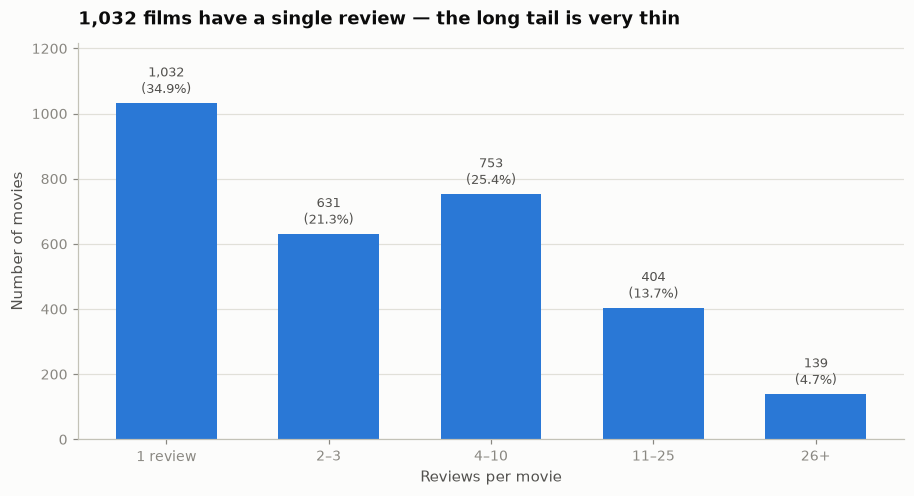

In [23]:
bucket_labels = ["1 review", "2–3", "4–10", "11–25", "26+"]
buckets = pd.cut(reviews_per_movie, bins=[0, 1, 3, 10, 25, np.inf], labels=bucket_labels)
bucket_counts = buckets.value_counts().reindex(bucket_labels)

fig, ax = plt.subplots(figsize=(8.4, 4.6))
bars = ax.bar(bucket_labels, bucket_counts.values, color=C1, width=0.62)
for bar, value in zip(bars, bucket_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 18, f"{value:,}\n({value / len(reviews_per_movie) * 100:.1f}%)",
            ha="center", va="bottom", fontsize=8.3, color=INK_2)
ax.set_ylim(0, bucket_counts.max() * 1.18)
ax.set_title("1,032 films have a single review — the long tail is very thin", loc="left", pad=12)
ax.set_xlabel("Reviews per movie")
ax.set_ylabel("Number of movies")
decorate(ax, grid_axis="y")
plt.tight_layout()
plt.show()

**Chart reading — review coverage.** Of 2,959 films, 1,032 (34.9%) have exactly one review, and more than half have three or fewer. At the other end, the top 10% of films hold 43.5% of all reviews. A review-embedding model trained on this table will have rich representations for a small set of popular films and almost no evidence for a third of the catalogue — a classic cold-start and popularity-bias problem for *Guess You Like*.

## 13. PII and Privacy Risks

We checked the raw table for direct identifiers in both columns and free text. The check covers reviewer names, email addresses, URLs, phone/fax/pager numbers, and IP-like strings. Counts are computed on the raw file; examples are masked so that no real personal data is printed.

**Direct identifiers found:**

- `reviewer_name` is a personal byline for **1,218 distinct people**. 41 of these byline values themselves contain an email address (for example, `user@domain (Name)` patterns).
- **5,118 reviews (27.1%) contain at least one email address**, with 7,159 total mentions and 395 distinct addresses. Many are critic signatures and contact lines; the table below counts reviews with more than one address.
- **8,160 reviews contain a URL**, which can identify a critic's personal site or archive.
- **41 reviews contain phone/fax/pager-like numbers** and **2 reviews contain IP-like strings**; inspection confirmed these are genuine contact details or mail-header remnants, not random numbers.
- Signatures also contain city/state and employer/affiliation text. These are **indirect identifiers** that can support re-identification when combined with a byline.

**No explicit `user_id`, `email`, `username`, `location`, or `ip_address` column exists.** The risk is concentrated in free text and the byline column.

**Treatment applied in this notebook:**

1. Every email, URL, phone-like number, and IP-like string is replaced with a typed placeholder (`[EMAIL_REDACTED]`, etc.) in `review_text_clean`.
2. Reviewer bylines are replaced by a truncated SHA-256 pseudonym (`critic_…`); the raw `reviewer_name` column is dropped from the exported cleaned file.
3. No raw review text or reviewer name is displayed in this notebook; samples are truncated and masked.
4. We do **not** claim that the cleaned text is anonymous. A critic may identify themselves, their employer, or a third party in the body of a review in ways that a regex cannot catch. The cleaned file should still be treated as sensitive and not published.

**Residual risks:** pseudonymisation is not anonymisation (especially for public critics whose bylines are searchable); free-text re-identification and linkage to external profiles remain possible; and the original raw file itself should not be committed to GitHub. This repository ignores `data/*.csv` for that reason.

In [24]:
raw_text = df_raw["review_text"].astype(str)
email_counts = raw_text.map(lambda s: len(EMAIL_RE.findall(s)))
unique_emails = {match for s in raw_text for match in EMAIL_RE.findall(s)}
phone_like = raw_text.str.contains(PHONE_RE, regex=True)
ip_like = raw_text.str.contains(IP_RE, regex=True)
url_like = raw_text.str.contains(URL_RE, regex=True)
byline_emails = int(df_raw["reviewer_name"].str.contains("@", na=False).sum())

pii_table = pd.DataFrame([
    ("reviewer_name column", f"{df_raw.reviewer_name.notna().sum():,} values", "Direct personal bylines"),
    ("Bylines containing an email", f"{byline_emails:,}", "Direct identifier inside identifier field"),
    ("Reviews with >=1 email", f"{int((email_counts > 0).sum()):,} ({ (email_counts > 0).mean() * 100:.1f}%)", "Contact details in signatures"),
    ("Total email mentions", f"{int(email_counts.sum()):,}", f"{len(unique_emails):,} distinct addresses"),
    ("Reviews with >1 email", f"{int((email_counts > 1).sum()):,}", "Long signature blocks"),
    ("Reviews containing a URL", f"{int(url_like.sum()):,}", "Personal sites / archives"),
    ("Reviews with phone/fax-like numbers", f"{int(phone_like.sum()):,}", "Contact details"),
    ("Reviews with IP-like strings", f"{int(ip_like.sum()):,}", "Mail headers"),
], columns=["Check", "Raw count", "Note"])
display(pii_table)

# Masked examples only
masked_examples = []
for s in raw_text[email_counts > 0].head(40):
    for match in EMAIL_RE.findall(s)[:1]:
        local, domain = match.split("@", 1)
        masked_examples.append(local[0] + "***@" + domain)
print("Masked email examples:", sorted(set(masked_examples))[:5])

phone_example = raw_text[phone_like].head(1).iloc[0]
if phone_example:
    match = PHONE_RE.search(phone_example)
    snippet = phone_example[max(0, match.start() - 40):match.end() + 20]
    print("Masked phone context:", re.sub(r"\d", "*", re.sub(EMAIL_RE, "[EMAIL]", snippet)))

print("\nVerification on the cleaned text:")
print(f"  emails remaining : {int(df_clean.review_text_clean.str.contains(EMAIL_RE, regex=True).sum()):,}")
print(f"  phones remaining : {int(df_clean.review_text_clean.str.contains(PHONE_RE, regex=True).sum()):,}")
print(f"  IPs remaining    : {int(df_clean.review_text_clean.str.contains(IP_RE, regex=True).sum()):,}")
print(f"  URLs remaining   : {int(df_clean.review_text_clean.str.contains(URL_RE, regex=True).sum()):,}")
print(f"  distinct reviewer bylines in df_clean: {df_clean.reviewer_name.nunique():,} (kept in memory only; dropped on export)")
print(f"  pseudonymous critic IDs     : {df_clean.reviewer_id.nunique():,}")

,Check,Raw count,Note
0,reviewer_name column,"18,862 values",Direct personal bylines
1,Bylines containing an email,41,Direct identifier inside identifier field
2,Reviews with >=1 email,"5,118 (27.1%)",Contact details in signatures
3,Total email mentions,"7,159",395 distinct addresses
4,Reviews with >1 email,"1,336",Long signature blocks
5,Reviews containing a URL,"8,160",Personal sites / archives
6,Reviews with phone/fax-like numbers,41,Contact details
7,Reviews with IP-like strings,2,Mail headers


Masked email examples: ['R***@indepen.com.', 'S***@InternetReviews.com', 'a***@computer.org', 'a***@excite.com', 'a***@freenet.carleton.ca']
Masked phone context: T
Organization: America Online, Inc. (*-***-***-****)
Lines: **
Sender: 

Verification on the cleaned text:
  emails remaining : 0
  phones remaining : 0
  IPs remaining    : 0
  URLs remaining   : 0
  distinct reviewer bylines in df_clean: 1,213 (kept in memory only; dropped on export)
  pseudonymous critic IDs     : 1,197


**Privacy conclusion.** The dataset is not PII-free. It contains a named critic for every review, contact details in a substantial minority of reviews, and indirect location/affiliation information in signatures. The notebook redacts direct contact patterns and pseudonymises bylines before export, but the free-text body can still contain identifying statements. This is acceptable for internal data-quality analysis; it would require a stronger governance review before any production use, and the raw CSV must not be committed to a public repository.

## 14. Bias and Sampling Risks

The data is **not a sample of streaming-service users**. It is a corpus of professional critic reviews, drawn largely from the `rec.arts.movies.reviews` Usenet archive and enriched with OMDb metadata. Several imbalances follow directly from that origin, and they matter for a *Guess You Like* feature.

The statistics below come from the cleaned table.

In [25]:
movie_counts = df_clean.groupby("movie_name").size().sort_values(ascending=False)
top10_movies = movie_counts.head(math.ceil(0.10 * len(movie_counts)))
bias_rows = [
    ("Source population", "Professional critics, not platform subscribers", "—", "Different rating behaviour and vocabulary"),
    ("Era coverage", "Reviews from films released 1990–1999", f"{(df_clean.year_api.between(1990, 1999)).mean() * 100:.1f}% of reviews", "Strong 1990s over-representation"),
    ("Era coverage", "Reviews from films released 2010 or later", f"{(df_clean.year_api >= 2010).mean() * 100:.1f}% of reviews", "Mostly metadata errors, not real coverage"),
    ("Movie popularity", "Films with exactly one review", f"{int((movie_counts == 1).sum()):,} of {len(movie_counts):,} films", "Long tail has almost no evidence"),
    ("Movie popularity", "Share of reviews held by top 10% of films", f"{df_clean.movie_name.isin(top10_movies.index).mean() * 100:.1f}%", "Popularity bias"),
    ("Critic concentration", "Share of reviews by top 1% of critics", f"{top1_share * 100:.1f}%", f"Gini = {gini:.2f}"),
    ("Genre", "Share of reviews in the top three genres", f"{df_clean.first_genre_clean.isin(['Comedy', 'Action', 'Drama']).mean() * 100:.1f}%", "Minority genres under-sampled"),
    ("Rating", "Share of rated reviews that are R", f"{(df_clean.rated_clean == 'R').mean() * 100:.1f}% of all rows", "Adult-oriented catalogue"),
    ("Gender", "First-listed director is male", f"{(df_clean.first_director_gender == 'male').mean() * 100:.1f}%", "Representation imbalance"),
    ("Gender", "First-listed actor is male", f"{(df_clean.first_actor_gender == 'male').mean() * 100:.1f}%", "Representation imbalance"),
    ("Language", "Reviews in English", "No language column; corpus is English-only", "Cannot measure or correct language balance"),
    ("Geography", "Critic country", "No country field; US-centric Usenet culture", "Cannot measure or correct geography"),
]
display(pd.DataFrame(bias_rows, columns=["Dimension", "Measure", "Value", "Risk"]))

,Dimension,Measure,Value,Risk
0,Source population,"Professional critics, not platform subscribers",—,Different rating behaviour and vocabulary
1,Era coverage,Reviews from films released 1990–1999,65.3% of reviews,Strong 1990s over-representation
2,Era coverage,Reviews from films released 2010 or later,5.9% of reviews,"Mostly metadata errors, not real coverage"
3,Movie popularity,Films with exactly one review,"1,032 of 2,959 films",Long tail has almost no evidence
4,Movie popularity,Share of reviews held by top 10% of films,43.5%,Popularity bias
5,Critic concentration,Share of reviews by top 1% of critics,33.8%,Gini = 0.86
6,Genre,Share of reviews in the top three genres,67.4%,Minority genres under-sampled
7,Rating,Share of rated reviews that are R,47.5% of all rows,Adult-oriented catalogue
8,Gender,First-listed director is male,85.0%,Representation imbalance
9,Gender,First-listed actor is male,70.5%,Representation imbalance


### How these biases would reach *Guess You Like*

- **Popularity bias.** With 1,032 films holding one review and the top 10% of films holding 43.5% of the corpus, any embedding or similarity score is far better estimated for blockbusters. Recommendations will drift toward films that are already popular, which reinforces themselves and makes the long tail effectively invisible. This is the classic "rich get richer" failure of collaborative and content-based recommenders.
- **Critic-versus-viewer bias.** Critics write long, analytical reviews and may value different qualities from casual subscribers. A model that learns "similar" from critic language may recommend acclaimed films that subscribers do not actually finish. This directly threatens retention, the business goal, even though this assignment cannot measure retention.
- **Era bias.** 65.3% of reviews concern 1990s films. Similarity will be dominated by that decade's genres, stars, and reviewing conventions; a new release may have no comparable neighbours.
- **Genre and rating imbalance.** Comedy/Action/Drama dominate 67.4% of rows, and R-rated films dominate the rated subset. Niche genres and family films are under-represented, so their neighbours are noisy.
- **Language and geography.** The corpus is English-only and US-centric. A platform serving multiple languages cannot use this data to represent non-English titles or audiences; translation and localisation effects are invisible.
- **Gender representation.** Male first-listed actors (70.5%) and directors (85.0%) dominate the metadata. If gender is used as a feature, the model will encode the imbalance; if it is not used, the imbalance still shapes which films are represented and connected.
- **Metadata-error bias.** The 315 titles with impossible `year_api` values are not random: they tend to be remakes or titles shared across years. Any year- or title-based similarity will propagate those confusions.

The correct response is not to "balance" the dataset by fabricating rows, but to (a) keep the imbalance visible with flags, (b) weight or evaluate by group, and (c) collect platform-user behaviour and non-English data before claiming the feature works.

## 15. Cleaned Dataset Summary

The cleaned table is the result of the decisions above. It is **not** a claim that the data is perfect: missing metadata is still missing, outliers are flagged rather than removed, and metadata errors remain visible through flags.

The before/after table below compares row count, columns, missing cells, duplicates, outliers, and entity counts.

In [26]:
summary = pd.DataFrame([
    ("Rows", f"{len(df_raw):,}", f"{len(df_clean):,}", "21 unusable reviews + 122 duplicate texts removed"),
    ("Columns", f"{df_raw.shape[1]:,}", f"{df_clean.shape[1]:,}", "1 redundant index dropped; 16 derived/flag columns added"),
    ("Missing cells (all columns)", f"{int(df_raw.isna().sum().sum()):,}", f"{int(df_clean.isna().sum().sum()):,}", "Row removal only; no numeric imputation"),
    ("Duplicate review texts", f"{int(df_raw.review_text.duplicated().sum()):,}", "0", "Exact duplicates removed after standardisation"),
    ("Reviews shorter than 100 chars", "21", "0", "Footer-only records removed"),
    ("Long reviews (> IQR fence)", "—", f"{int(df_clean.long_review.sum()):,}", "Kept and flagged, not removed"),
    ("Distinct movies", f"{df_raw.movie_name.nunique():,}", f"{df_clean.movie_name.nunique():,}", "3 films had only an unusable review"),
    ("Distinct reviewer identities", f"{df_raw.reviewer_name.str.lower().str.strip().nunique():,}", f"{df_clean.reviewer_id.nunique():,}", "Case variants merged; bylines hashed"),
    ("Reviews with an email in text", f"{int((email_counts > 0).sum()):,}", "0", "Redacted, not removed"),
    ("Release years flagged impossible", f"{int((df_raw.year_api > 2001).sum()):,}", f"{int(df_clean.release_year_suspect.sum()):,}", "Flagged; excluded from year analysis"),
], columns=["Metric", "Before", "After", "Note"])
display(summary)

print("Cleaned dtypes:")
display(df_clean.dtypes.astype(str).to_frame("dtype"))

print("\nFlag counts in the cleaned table:")
flags = ["rated_missing", "year_missing", "long_review", "high_review_count_movie",
         "review_year_implausible", "release_year_suspect", "year_before_release"]
display(df_clean[flags].sum().to_frame("rows_flagged"))
print(f"High-volume movies: {int(high_volume_movies.sum()):,} films covering {int(df_clean.high_review_count_movie.sum()):,} reviews")

,Metric,Before,After,Note
0,Rows,"18,862","18,719",21 unusable reviews + 122 duplicate texts removed
1,Columns,20,35,1 redundant index dropped; 16 derived/flag columns added
2,Missing cells (all columns),"5,690","5,644",Row removal only; no numeric imputation
3,Duplicate review texts,116,0,Exact duplicates removed after standardisation
4,Reviews shorter than 100 chars,21,0,Footer-only records removed
5,Long reviews (> IQR fence),—,620,"Kept and flagged, not removed"
6,Distinct movies,"2,962","2,959",3 films had only an unusable review
7,Distinct reviewer identities,"1,202","1,197",Case variants merged; bylines hashed
8,Reviews with an email in text,"5,118",0,"Redacted, not removed"
9,Release years flagged impossible,"1,750","1,732",Flagged; excluded from year analysis


Cleaned dtypes:


,dtype
review_id,int64
movie_name,object
year,float64
reviewer_name,object
review_text,object
rated,object
year_api,int64
genre,object
directors,object
writers,object



Flag counts in the cleaned table:


,rows_flagged
rated_missing,1648
year_missing,366
long_review,620
high_review_count_movie,7446
review_year_implausible,1400
release_year_suspect,1732
year_before_release,8091


High-volume movies: 256 films covering 7,446 reviews


**Before/after, in plain terms.**

- Rows: **18,862 → 18,719** (−143, −0.76%): 21 footer-only/invalid reviews and 122 duplicate review texts.
- Columns: **20 → 35** in the working table (33 columns are exported). One redundant index was dropped; the new columns are the cleaned text, its length, harmonised genre/rating/title fields, a pseudonymous critic ID, three missing/failure flags, three year-consistency flags, and two review-volume features. No original review or metadata column was overwritten.
- Missing cells: **5,690 → 5,644** (a small drop purely from the 143 removed rows). Missing metadata is still present and flagged; it was not imputed.
- Duplicate review texts: **116 raw (122 after standardisation) → 0**.
- Outliers: **620 long reviews flagged, none removed**; 256 high-review-count films flagged. The `high_review_count_movie` row count (7,446) is larger than the film count because it marks every review belonging to those 256 films.
- Distinct movies: **2,962 → 2,959**; distinct critic identities: **1,218 → 1,197** (case variants merged and rows removed).
- PII: **5,118 reviews with email addresses → 0**; reviewer bylines replaced by hashes.

### Cleaning decision table

| Issue | Evidence (actual) | Treatment | Reason |
|---|---|---|---|
| Review text is only the legal footer | 19 records (0.10%) become empty after footer removal; 21 are < 100 chars | Drop 21 rows | No review content to analyse; 0.11% loss is negligible |
| Missing rating | 1,661 (8.81%) raw; 1,648 after full cleaning | Fill `"Unknown"` + `rated_missing` flag | Keeps reviews; missingness is informative (documentaries) and should not be silently deleted |
| Missing genre | 7 (0.04%) | Fill `"Unknown"` | Explicit category preserves the row without inventing a genre |
| Missing director/writer/actor/plot | 330 / 953 / 215 / 648 | Keep null | List/free-text metadata cannot be honestly reconstructed |
| Missing `year` | 371 (1.97%) | Keep null + `year_missing` flag | No meaningful median; imputation would fabricate chronology |
| Exact duplicate rows | 0 | None | — |
| Duplicate review text | 116 raw; 122 after standardisation | Drop later copies (122) | Same observation counted twice; 5 cross-movie groups prove label errors |
| Multiple reviews per movie | 2,962 films; median 3; max 80 | Keep | Legitimate repeated observations by different critics |
| Long reviews | 620 (3.31%) above upper IQR fence 7,925 | Keep + `long_review` flag | Long-form reviews are valid; text models can chunk |
| Many reviews per movie | 256 films above fence; max 80 | Keep + `high_review_count_movie` flag | Popularity is real, not an error; retained as bias evidence |
| Prolific critics | Top 1% = 33.8% of reviews; Gini 0.86 | Keep; analyse as bias | Removing prolific critics would bias the corpus differently |
| `year` < 1982 | 1,400 (7.48%) | Flag `review_year_implausible` | Impossible for this Usenet archive; likely parsing errors |
| `year_api` > 2001 | 1,732 (9.25%), 315 titles | Flag `release_year_suspect`; exclude from year analysis | Reviews cannot postdate 2001; OMDb mismatch |
| `year` before release | 8,091 (43.2%) | Flag `year_before_release`; no imputation | The two year fields conflict; both are unreliable at row level |
| 19 rating labels | 19 → 13 after mapping | Harmonise documented legacy codes | Same certificate should not split into several categories |
| Genre order | 405 strings → 379 non-null sets (380 with `Unknown`); 859 rows reordered | Sort the genre set | Cosmetic ordering created duplicate categories |
| Inverted titles | 150 titles (`"Matrix, The"`) | Move article to front | Consistent entity display, zero collisions |
| Aggressive title folding | 6 collision groups (e.g. `Gun Crazy` / `Guncrazy`) | **Do not merge** | Would incorrectly combine distinct films |
| HTML / mojibake / footer | 151 / 9 / 18,862 records | Strip, repair, remove footer | Artefacts distort text and length |
| Emails / URLs / phones / IPs | 5,118 / 8,160 / 41 / 2 reviews | Redact with typed placeholders | Direct or indirect personal identifiers |
| Reviewer byline | 1,218 people; 41 contain emails | Hash to `reviewer_id`; drop raw name on export | Identity not needed downstream; privacy |
| Redundant index | `Unnamed: 0` equals row index | Drop column | Duplicate identifier |
| Documentation mismatch | Claim 17,165 / 2,544; file 18,862 / 2,962 | Report actual values | Do not trust unverified metadata |

In [27]:
EXPORT_COLUMNS = [
    "review_id", "movie_name", "movie_title_clean", "year", "year_api",
    "rated", "rated_clean", "rated_missing", "genre", "genre_clean",
    "first_genre", "first_genre_clean", "directors", "writers", "actors", "plot",
    "first_actor", "first_director", "first_writer",
    "first_actor_gender", "first_director_gender", "first_writer_gender",
    "review_text_clean", "review_len", "reviewer_id",
    "year_missing", "review_year_implausible", "release_year_suspect", "year_before_release",
    "long_review", "movie_review_count", "high_review_count_movie", "reviewer_review_count",
]
clean_export = df_clean[EXPORT_COLUMNS].copy()
out_path = DATA_DIR / "cleaned_movie_reviews.csv"
clean_export.to_csv(out_path, index=False)

print(f"Saved cleaned dataset: {out_path} ({out_path.stat().st_size / 1e6:.1f} MB)")
print(f"Rows x columns: {clean_export.shape[0]:,} x {clean_export.shape[1]}")
print(f"Contains raw reviewer_name : {'reviewer_name' in clean_export.columns}")
print(f"Contains raw review_text   : {'review_text' in clean_export.columns}")
print(f"Emails remaining in export : {int(clean_export.review_text_clean.str.contains(EMAIL_RE, regex=True).sum()):,}")
print(f"Rows with any PII column   : {int(clean_export.reviewer_id.notna().sum()):,} pseudonymous IDs")

Saved cleaned dataset: data\cleaned_movie_reviews.csv (83.2 MB)
Rows x columns: 18,719 x 33
Contains raw reviewer_name : False
Contains raw review_text   : False
Emails remaining in export : 0
Rows with any PII column   : 18,719 pseudonymous IDs


The cleaned file is written to `data/cleaned_movie_reviews.csv` (relative path). It is **not** intended to be committed to GitHub; the repository's `.gitignore` excludes `data/*.csv`. It can be regenerated at any time by running this notebook from the raw download.

## 16. Conclusion and Limitations

**Is the data fit for a future review-analysis and similar-movie recommendation pipeline?** It is **usable for text analysis after the treatments above**, but it is **not fit to be used unchanged** as the sole input to an automated *Guess You Like* pipeline. The core review table is keyed and complete, and 18,719 reviews retain substantive text. However, 9.3% of rows carry impossible release years, 8.8% lack a rating, 34.9% of films have a single review, and the corpus is a 1990s English-language critic sample rather than platform-user behaviour. A pipeline that ignores these facts will produce confident but misleading similarities.

**What problems remain after cleaning?**

1. **Missing metadata is still missing.** Genre, director, writer, actor, and plot values remain null for 0.04%–5.05% of rows; rating is unknown for 1,648 reviews. They are flagged or filled with `Unknown`, not imputed.
2. **The year fields are not reconciled.** `year` is a row-level field with 7.5% impossible values, and `year_api` has 315 suspect titles. We flag both and exclude suspect rows from year-based analysis, but the true release year is still unknown for those films.
3. **Metadata matching errors remain.** Identical review text appearing under different movies (5 groups) and impossible OMDb years (315 titles) show that some movie labels are wrong. We cannot repair them without an external title authority.
4. **Outliers are retained.** 620 long reviews and 256 high-volume films are still in the data, deliberately, because they are real. Any model must handle length and popularity skew explicitly.
5. **PII is reduced, not eliminated.** Direct contact details and bylines are redacted/pseudonymised, but free text may still identify people, and the raw CSV remains sensitive.

**Are there representativeness limitations?** Yes, and they are severe for the business scenario. The data comes from professional critics, not streaming subscribers; it is English-only; it is concentrated in 1990s releases; it over-represents popular films and a small number of prolific critics; and it contains almost no evidence for a third of the catalogue. These are sampling biases, not bugs that cleaning can remove.

**What should be done before modelling?**

- Replace the critic corpus with (or at least augment it with) platform-user reviews and behavioural signals such as watch completion, likes, and skips.
- Build a proper movie dimension with a stable `movie_id` and an authoritative title/year source; re-resolve the 315 suspect titles.
- Decide explicitly how to handle missing ratings (separate `Unknown` category, not zero) and long reviews (chunking, not truncation to a mean).
- Evaluate recommendations by popularity stratum and genre so that long-tail performance is visible; report coverage and diversity alongside accuracy.
- Obtain a legal/privacy review before exporting any review text containing bylines or signatures.

**What this assignment does *not* show.** This notebook performs **data profiling, EDA, and data-quality handling only**. It does **not** implement a recommendation system, train or fine-tune a pre-trained model, evaluate recommendation accuracy, or demonstrate any improvement in user retention. The *Guess You Like* feature is the motivating business context; no claim is made that cleaning this dataset would improve retention, and no algorithm is compared. Any statement about recommendation effectiveness would require a separate modelling study with user-behaviour data and a proper evaluation design.

## 17. Instructions to Run the Notebook

**Prerequisites:** Python 3.10+ and Jupyter. The tested environment is Python 3.13 with pandas 2.2, NumPy 2.1, and Matplotlib 3.10 (see `requirements.txt`).

1. Clone the repository and open a terminal in the project folder.
2. Create and activate a virtual environment (optional but recommended):
   ```bash
   python -m venv .venv
   # Windows
   .venv\Scripts\activate
   # macOS / Linux
   source .venv/bin/activate
   ```
3. Install dependencies:
   ```bash
   pip install -r requirements.txt
   ```
4. Start Jupyter:
   ```bash
   jupyter notebook
   ```
5. Open `Assignment1_EDA.ipynb` and choose **Kernel → Restart & Run All** (or *Run All Cells*).
6. The first run downloads `data/movie_reviews.csv` automatically (about 94 MB) from Zenodo. If the network blocks the download, download the file manually from
   <https://zenodo.org/records/14203180/files/movie_reviews.csv?download=1>
   and save it as `data/movie_reviews.csv`, then re-run.
7. The notebook writes `data/cleaned_movie_reviews.csv` at the end. That file is git-ignored and can be regenerated.

**Expected runtime:** a few minutes on a normal laptop, dominated by the one-time download. After the file is cached, a full re-run takes well under a minute.

**Troubleshooting**

- `RuntimeError: Dataset download failed` — check the URL in a browser, download manually as above, and confirm the file is at `data/movie_reviews.csv`.
- `ValueError: Unexpected schema` — the downloaded file is not the expected dataset; delete it and re-download.
- Missing fonts or a non-interactive backend — the notebook uses Matplotlib's default `DejaVu Sans`, which ships with Matplotlib; it does not require extra font installation.
- The SHA-256 warning — the Zenodo file may have been updated; the analysis will still run on the real file, but statistics may differ from the values quoted here.